<a href="https://colab.research.google.com/github/Chavaper/Deteccion-de-neumonia-aplicando-Deep-Learning/blob/main/notebook/deteccion_neumonia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Detección de neumonía

**Contexto**

asdf


Problema

asdf

**Pregunta a responder**: ¿Qué resolución mínima necesita un modelo para detectar neumonía con buen rendimiento?

# Paso 1 · Datos: PneumoniaMNIST en 4 resoluciones

**Pregunta de investigación:** ¿qué resolución mínima necesita un modelo para detectar neumonía con buen rendimiento, y cuál conviene desplegar en una app web?

Este notebook:

1. Descarga PneumoniaMNIST en **28, 64, 128 y 224 px** con las particiones oficiales (train / val / test).
2. Verifica los datos y analiza el **desbalance de clases**.
3. Calcula los **pesos por clase** para la función de pérdida.
4. Define el **preprocesamiento y el aumento de datos** (rotaciones pequeñas y brillo/contraste, sin volteos horizontales).
5. Guarda todo en un módulo `pneumonia_data.py` que reutilizarán el entrenamiento (paso 2) y la app web, para que el preprocesamiento sea **idéntico** en todas partes.
6. Genera las figuras que irán al informe.

> Para este paso no hace falta GPU, pero conviene activarla ya (*Entorno de ejecución → Cambiar tipo de entorno → T4 GPU*), porque el paso 2 sí la necesita.

In [6]:
%pip install -q medmnist

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 12.6 MB/s eta 0:00:00


In [7]:
import os, sys, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torchvision
import medmnist

print(f"medmnist {medmnist.__version__} | torch {torch.__version__} | torchvision {torchvision.__version__}")
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no disponible (no hace falta en este paso)")

medmnist 3.0.2 | torch 2.11.0+cu130 | torchvision 0.26.0+cu130
GPU: Tesla T4


## 1. Configuración

Con `USE_DRIVE = True` los datos, figuras y (más adelante) los modelos se guardan en tu Google Drive y sobreviven cuando Colab se reinicia. Con `False` todo queda en `/content` y se pierde al cerrar la sesión.

In [8]:
USE_DRIVE = True   # recomendado: el proyecto durará varios días
DOWNLOAD = True    # descarga los .npz desde Zenodo la primera vez (luego los reutiliza)
SEED = 42
SIZES = [28, 64, 128, 224]

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = "/content/drive/MyDrive/neumonia_resolucion"
else:
    PROJECT_DIR = "/content/neumonia_resolucion"

DATA_DIR = os.path.join(PROJECT_DIR, "data")
FIG_DIR = os.path.join(PROJECT_DIR, "outputs", "figuras")
for d in (DATA_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)
print("Proyecto en:", PROJECT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Proyecto en: /content/drive/MyDrive/neumonia_resolucion


## 2. Módulo de preprocesamiento compartido

La siguiente celda escribe `pneumonia_data.py` en la carpeta del proyecto. **Todo** el preprocesamiento vive ahí:

- `get_transforms(train=True)`: aumento suave + conversión a 3 canales + normalización ImageNet (los modelos están preentrenados en ImageNet).
- `get_transforms(train=False)`: solo conversión y normalización, para validación, prueba y la app.
- `to_model_input(img, size)`: convierte una radiografía cualquiera (como la que subirá el médico) al mismo formato que MedMNIST: escala de grises, recorte cuadrado central y redimensionado.

Si cambias algo del preprocesamiento, cámbialo solo aquí.

In [9]:
%%writefile {PROJECT_DIR}/pneumonia_data.py
"""Preprocesamiento compartido de PneumoniaMNIST: entrenamiento, evaluación y app web."""
import os
import random

import numpy as np
import torch
from PIL import Image
from torch.utils.data import DataLoader
from torchvision import transforms as T
from medmnist import PneumoniaMNIST

SIZES = (28, 64, 128, 224)
CLASS_NAMES = ("normal", "neumonía")          # 0 = normal, 1 = neumonía
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

# Aumento de datos suave (solo entrenamiento). Sin volteo horizontal:
# invertir una radiografía de tórax cambia la lateralidad (p. ej. el corazón).
ROTATION_DEG = 10
BRIGHTNESS = 0.10
CONTRAST = 0.10


def set_seed(seed: int = 42) -> None:
    """Fija todas las semillas para que los experimentos sean reproducibles."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def get_transforms(train: bool) -> T.Compose:
    """Transformaciones para una imagen PIL en escala de grises."""
    common = [
        T.Grayscale(num_output_channels=3),   # 1 canal -> 3 canales (modelos ImageNet)
        T.ToTensor(),                          # [0, 255] -> [0, 1]
        T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]
    if not train:
        return T.Compose(common)
    augment = [
        T.RandomRotation(ROTATION_DEG, fill=0),
        T.ColorJitter(brightness=BRIGHTNESS, contrast=CONTRAST),
    ]
    return T.Compose(augment + common)


def to_model_input(img: Image.Image, size: int) -> Image.Image:
    """Lleva una radiografía arbitraria al formato de MedMNIST:
    escala de grises, recorte cuadrado central y redimensionado a size x size.
    Úsala en la app antes de get_transforms(train=False)."""
    img = img.convert("L")
    w, h = img.size
    side = min(w, h)
    left, top = (w - side) // 2, (h - side) // 2
    img = img.crop((left, top, left + side, top + side))
    return img.resize((size, size), Image.BICUBIC)


def _to_int_label(y) -> int:
    return int(np.asarray(y).ravel()[0])


def load_split(split: str, size: int, root: str, download: bool = True, augment: bool = None):
    """Carga una partición oficial ('train', 'val' o 'test') en la resolución indicada.
    Por defecto solo 'train' lleva aumento de datos."""
    if size not in SIZES:
        raise ValueError(f"size debe ser uno de {SIZES}")
    os.makedirs(root, exist_ok=True)
    if augment is None:
        augment = split == "train"
    return PneumoniaMNIST(
        split=split, size=size, root=root, download=download,
        transform=get_transforms(train=augment), target_transform=_to_int_label,
    )


def class_counts(dataset) -> np.ndarray:
    return np.bincount(dataset.labels.ravel(), minlength=len(CLASS_NAMES))


def class_weights(train_dataset) -> torch.Tensor:
    """Pesos inversamente proporcionales a la frecuencia: N / (n_clases * n_c).
    Se pasan a nn.CrossEntropyLoss(weight=...). Se calculan SOLO con train."""
    counts = class_counts(train_dataset)
    weights = counts.sum() / (len(counts) * counts)
    return torch.tensor(weights, dtype=torch.float32)


def _seed_worker(worker_id: int) -> None:
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_loaders(size: int, root: str, batch_size: int = 64, seed: int = 42,
                 num_workers: int = 2, download: bool = True):
    """Devuelve los DataLoaders train/val/test de una resolución.
    Mismo batch_size para todas las resoluciones = misma configuración de entrenamiento."""
    datasets = {s: load_split(s, size, root, download) for s in ("train", "val", "test")}
    g = torch.Generator()
    g.manual_seed(seed)
    pin = torch.cuda.is_available()
    loaders = {
        s: DataLoader(
            ds, batch_size=batch_size, shuffle=(s == "train"),
            num_workers=num_workers, pin_memory=pin,
            worker_init_fn=_seed_worker, generator=g,
        )
        for s, ds in datasets.items()
    }
    return loaders, datasets

Overwriting /content/drive/MyDrive/neumonia_resolucion/pneumonia_data.py


In [10]:
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)
import importlib, pneumonia_data as pdata
importlib.reload(pdata)
pdata.set_seed(SEED)
print("Módulo listo:", pdata.__file__)

Módulo listo: /content/drive/MyDrive/neumonia_resolucion/pneumonia_data.py


## 3. Descarga y verificación de las 4 resoluciones

Se descargan los archivos oficiales (unos 5 MB a 28 px y unos 300 MB a 224 px en total). Luego se comprueba que:

- cada partición tenga el número de imágenes oficial (4.708 / 524 / 624);
- las **etiquetas sean idénticas en las 4 resoluciones**, es decir, que son las mismas radiografías y solo cambia la resolución. Esto es lo que hace válida la comparación.

In [11]:
EXPECTED = {"train": 4708, "val": 524, "test": 624}
raw = {}   # raw[size][split] -> dataset sin aumento (para análisis y figuras)
rows = []

for size in SIZES:
    t0 = time.time()
    raw[size] = {s: pdata.load_split(s, size, DATA_DIR, download=DOWNLOAD, augment=False)
                 for s in ("train", "val", "test")}
    for split, ds in raw[size].items():
        n = len(ds)
        assert n == EXPECTED[split], f"{size}px/{split}: {n} imágenes, se esperaban {EXPECTED[split]}"
        counts = pdata.class_counts(ds)
        rows.append({
            "resolución": f"{size}px", "partición": split, "imágenes": n,
            "normal": counts[0], "neumonía": counts[1],
            "% neumonía": round(100 * counts[1] / n, 1),
            "forma": "×".join(map(str, ds.imgs.shape[1:])), "dtype": str(ds.imgs.dtype),
        })
    print(f"{size:>3}px listo en {time.time() - t0:.1f} s")

# Mismas imágenes en todas las resoluciones -> mismas etiquetas
for split in EXPECTED:
    ref = raw[SIZES[0]][split].labels
    for size in SIZES[1:]:
        assert np.array_equal(ref, raw[size][split].labels), f"Etiquetas distintas en {size}px/{split}"
print("Conteos oficiales correctos y etiquetas idénticas en las 4 resoluciones")

summary = pd.DataFrame(rows)
summary

 28px listo en 1.4 s
 64px listo en 2.3 s
128px listo en 4.4 s
224px listo en 15.0 s
Conteos oficiales correctos y etiquetas idénticas en las 4 resoluciones


,resolución,partición,imágenes,normal,neumonía,% neumonía,forma,dtype
0,28px,train,4708,1214,3494,74.2,28×28,uint8
1,28px,val,524,135,389,74.2,28×28,uint8
2,28px,test,624,234,390,62.5,28×28,uint8
3,64px,train,4708,1214,3494,74.2,64×64,uint8
4,64px,val,524,135,389,74.2,64×64,uint8
5,64px,test,624,234,390,62.5,64×64,uint8
6,128px,train,4708,1214,3494,74.2,128×128,uint8
7,128px,val,524,135,389,74.2,128×128,uint8
8,128px,test,624,234,390,62.5,128×128,uint8
9,224px,train,4708,1214,3494,74.2,224×224,uint8


## 4. Desbalance de clases y pesos de la pérdida

Como las etiquetas son iguales en todas las resoluciones, la distribución de clases también lo es; basta con analizarla una vez. Los pesos se calculan **solo con el conjunto de entrenamiento** y se usarán en `nn.CrossEntropyLoss(weight=...)` en el paso 2.

train: normal= 1214  neumonía= 3494  ratio neumonía/normal=2.88
  val: normal=  135  neumonía=  389  ratio neumonía/normal=2.88
 test: normal=  234  neumonía=  390  ratio neumonía/normal=1.67

Pesos de la pérdida -> normal: 1.939 | neumonía: 0.674


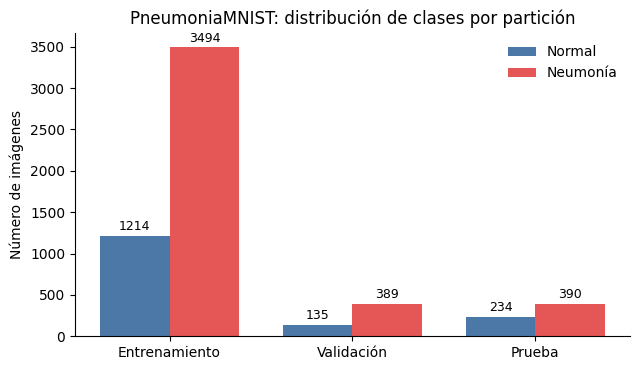

Configuración guardada en data_config.json


In [12]:
split_counts = {s: pdata.class_counts(raw[SIZES[0]][s]) for s in ("train", "val", "test")}
weights = pdata.class_weights(raw[SIZES[0]]["train"])

for s, c in split_counts.items():
    print(f"{s:>5}: normal={c[0]:>5}  neumonía={c[1]:>5}  ratio neumonía/normal={c[1] / c[0]:.2f}")
print(f"\nPesos de la pérdida -> normal: {weights[0]:.3f} | neumonía: {weights[1]:.3f}")

# Figura para el informe
fig, ax = plt.subplots(figsize=(6.5, 3.8))
x = np.arange(3)
bw = 0.38
normal = [split_counts[s][0] for s in ("train", "val", "test")]
neumo = [split_counts[s][1] for s in ("train", "val", "test")]
b1 = ax.bar(x - bw / 2, normal, bw, label="Normal", color="#4C78A8")
b2 = ax.bar(x + bw / 2, neumo, bw, label="Neumonía", color="#E45756")
ax.bar_label(b1, padding=2, fontsize=9)
ax.bar_label(b2, padding=2, fontsize=9)
ax.set_xticks(x, ["Entrenamiento", "Validación", "Prueba"])
ax.set_ylabel("Número de imágenes")
ax.set_title("PneumoniaMNIST: distribución de clases por partición")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig1_distribucion_clases.png"), dpi=200)
plt.show()

# Guardar la configuración de datos para los siguientes pasos
data_config = {
    "dataset": "PneumoniaMNIST (MedMNIST v2 / MedMNIST+)",
    "sizes": SIZES, "seed": SEED, "class_names": list(pdata.CLASS_NAMES),
    "split_counts": {s: c.tolist() for s, c in split_counts.items()},
    "class_weights": weights.tolist(),
    "augmentation": {"rotation_deg": pdata.ROTATION_DEG, "brightness": pdata.BRIGHTNESS,
                     "contrast": pdata.CONTRAST, "horizontal_flip": False},
    "normalization": {"mean": pdata.IMAGENET_MEAN, "std": pdata.IMAGENET_STD},
}
with open(os.path.join(PROJECT_DIR, "data_config.json"), "w", encoding="utf-8") as f:
    json.dump(data_config, f, indent=2, ensure_ascii=False)
print("Configuración guardada en data_config.json")

## 5. La misma radiografía en las 4 resoluciones

Esta figura resume visualmente la pregunta de investigación: cuánta información se pierde al bajar la resolución. Es buena candidata para la introducción o la metodología del informe.

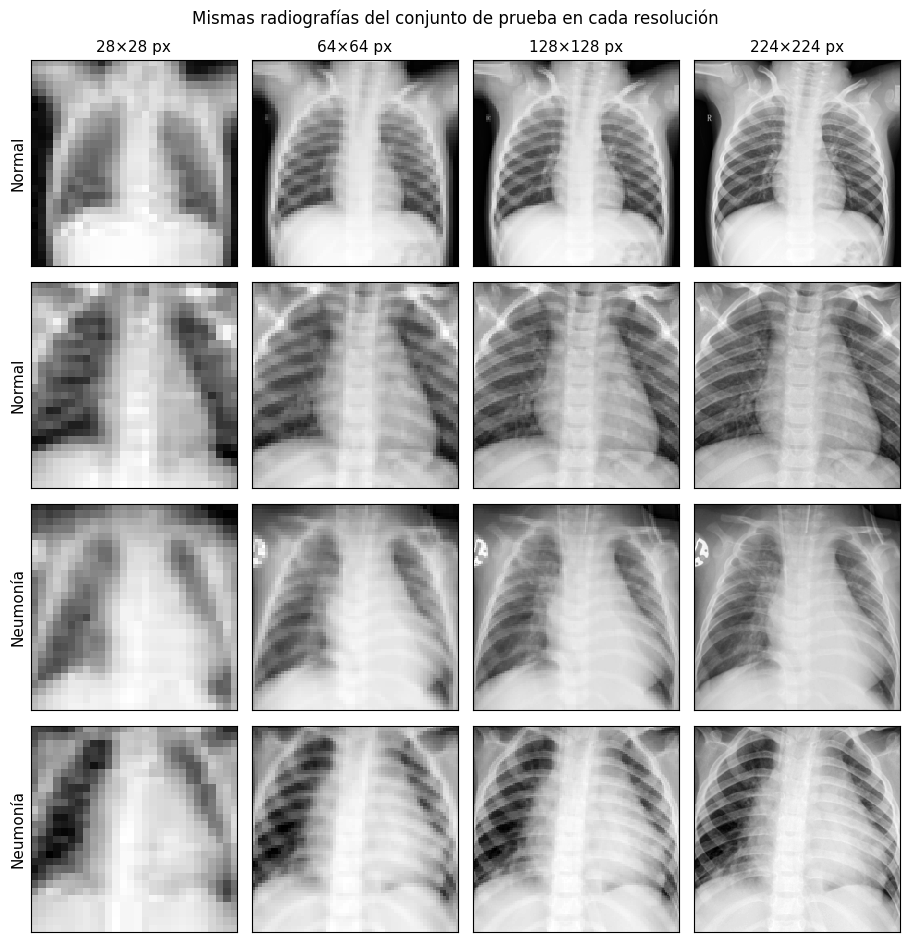

In [13]:
rng = np.random.default_rng(SEED)
test_labels = raw[SIZES[0]]["test"].labels.ravel()
idx = np.concatenate([rng.choice(np.where(test_labels == c)[0], 2, replace=False) for c in (0, 1)])

fig, axes = plt.subplots(len(idx), len(SIZES), figsize=(2.3 * len(SIZES), 2.4 * len(idx)))
for r, i in enumerate(idx):
    for c, size in enumerate(SIZES):
        ax = axes[r, c]
        ax.imshow(raw[size]["test"].imgs[i], cmap="gray", interpolation="nearest")
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            ax.set_title(f"{size}×{size} px", fontsize=11)
        if c == 0:
            ax.set_ylabel(pdata.CLASS_NAMES[test_labels[i]].capitalize(), fontsize=11)
fig.suptitle("Mismas radiografías del conjunto de prueba en cada resolución", fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig2_resoluciones.png"), dpi=200)
plt.show()

## 6. Comprobación del aumento de datos

Se aplica el aumento de entrenamiento 7 veces a una misma radiografía de 224 px. Las variaciones deben ser **sutiles y realistas**: si alguna se ve irreconocible o volteada, el aumento es demasiado agresivo.

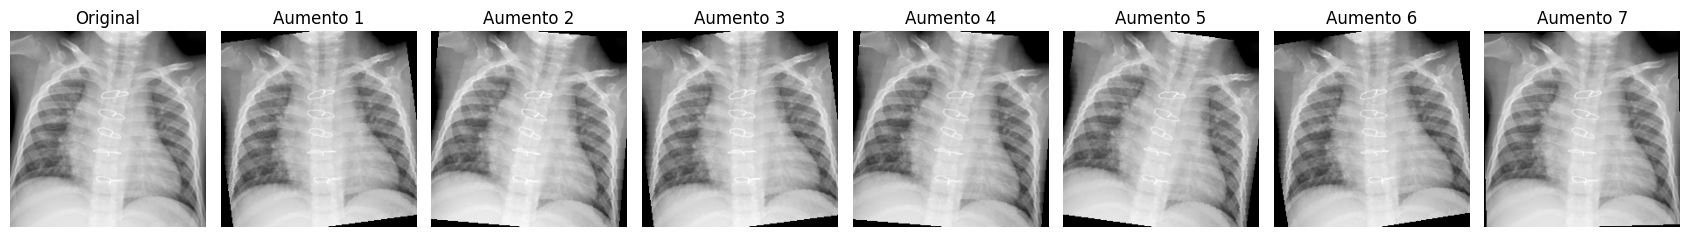

✔ Prueba determinista (sin aumento)


In [14]:
train_aug = pdata.load_split("train", 224, DATA_DIR, download=False, augment=True)
mean = torch.tensor(pdata.IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(pdata.IMAGENET_STD).view(3, 1, 1)
denorm = lambda t: (t * std + mean).clamp(0, 1)[0].numpy()   # un canal basta (los 3 son iguales)

i = int(np.where(train_aug.labels.ravel() == 1)[0][0])
fig, axes = plt.subplots(1, 8, figsize=(17, 2.6))
axes[0].imshow(train_aug.imgs[i], cmap="gray"); axes[0].set_title("Original")
pdata.set_seed(SEED)
for k in range(1, 8):
    x, _ = train_aug[i]
    axes[k].imshow(denorm(x), cmap="gray"); axes[k].set_title(f"Aumento {k}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig3_aumento_datos.png"), dpi=200)
plt.show()

# Validación y prueba NO deben llevar aumento: la misma imagen debe dar siempre el mismo tensor
test_ds = pdata.load_split("test", 224, DATA_DIR, download=False)
assert torch.equal(test_ds[0][0], test_ds[0][0]), "El conjunto de prueba no debería ser aleatorio"
print("✔ Prueba determinista (sin aumento)")

## 7. DataLoaders listos para entrenar

Se construyen los `DataLoader` de cada resolución con el **mismo `batch_size`** (misma configuración de entrenamiento para todas) y se revisa un lote de cada uno.

In [15]:
BATCH_SIZE = 64
checks = []
for size in SIZES:
    loaders, datasets = pdata.make_loaders(size, DATA_DIR, batch_size=BATCH_SIZE, seed=SEED, download=False)
    x, y = next(iter(loaders["train"]))
    t0 = time.time()
    n_batches = sum(1 for _ in loaders["train"])
    checks.append({
        "resolución": f"{size}px", "lote x": tuple(x.shape), "lote y": tuple(y.shape),
        "x.dtype": str(x.dtype), "y.dtype": str(y.dtype),
        "rango x": f"[{x.min():.2f}, {x.max():.2f}]",
        "batches/época (train)": n_batches,
        "s por época solo cargando": round(time.time() - t0, 1),
    })
    assert x.shape[1:] == (3, size, size) and y.dtype == torch.int64
pd.DataFrame(checks)

,resolución,lote x,lote y,x.dtype,y.dtype,rango x,batches/época (train),s por época solo cargando
0,28px,"(64, 3, 28, 28)","(64,)",torch.float32,torch.int64,"[-2.12, 2.64]",74,2.3
1,64px,"(64, 3, 64, 64)","(64,)",torch.float32,torch.int64,"[-2.12, 2.64]",74,2.8
2,128px,"(64, 3, 128, 128)","(64,)",torch.float32,torch.int64,"[-2.12, 2.64]",74,4.5
3,224px,"(64, 3, 224, 224)","(64,)",torch.float32,torch.int64,"[-2.12, 2.64]",74,8.7


## Resumen del paso 1

- Datos descargados en 4 resoluciones con las particiones oficiales, verificados y con etiquetas idénticas entre resoluciones.
- Desbalance cuantificado y pesos de la pérdida guardados en `data_config.json`.
- Preprocesamiento único en `pneumonia_data.py`, que importarán el entrenamiento y la app.
- Figuras para el informe en `outputs/figuras/`.

**Decisión pendiente para el paso 2.** Hay dos formas de alimentar a los modelos:

1. **Resolución nativa** (lo que prepara este notebook): cada modelo recibe 28, 64, 128 o 224 px. Mide a la vez la información de la imagen y el costo computacional real, que es lo que importa para elegir qué desplegar en la app. Como contrapartida, a 28 px las redes preentrenadas reducen la imagen a un mapa de 1×1 y trabajan lejos del tamaño para el que se preentrenaron.
2. **Reescalar todo a 224 px**: aísla solo la información perdida (la arquitectura ve siempre el mismo tamaño), pero el costo pasa a ser idéntico en todas las resoluciones.

Para la pregunta de investigación tal como está planteada, la opción 1 es la más coherente; la 2 puede añadirse como experimento complementario si sobra tiempo.

# **Paso 2: definición de los 3 modelos del estudio.**

Modelos (todos preentrenados en ImageNet, con la cabeza reemplazada por 2 clases):
  - resnet18         : referencia del paper original de MedMNIST.
  - efficientnet_b0  : modelo ligero pensado para la app web.
  - densenet121      : arquitectura muy usada en radiografía de tórax (p. ej. CheXNet).

Decisión metodológica (resolución nativa):
  Cada modelo recibe la imagen en su resolución nativa (28, 64, 128 o 224 px).
  Las tres arquitecturas reducen la imagen 32 veces, y DenseNet-121 directamente
  falla con entradas menores a 32 px. Por eso, SOLO las imágenes de 28 px se
  reescalan a 32 px dentro del modelo (MinSizeWrapper), de forma idéntica para
  los tres modelos. El reescalado aumenta los píxeles, no la información, así que
  la imagen sigue conteniendo lo mismo que la de 28 px. Esto debe declararse en
  la metodología del informe.

In [16]:
%%writefile {PROJECT_DIR}/models.py

import os
import tempfile

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models as tvm

MODEL_NAMES = ("resnet18", "efficientnet_b0", "densenet121")
NUM_CLASSES = 2
MIN_INPUT_SIZE = 32  # mínimo que aceptan las tres arquitecturas


class MinSizeWrapper(nn.Module):
    """Envuelve una red y reescala (bilineal) las entradas menores a min_size.
    Para 64, 128 y 224 px no hace nada. Al estar dentro del modelo, la app web
    hereda el mismo comportamiento automáticamente."""

    def __init__(self, net: nn.Module, min_size: int = MIN_INPUT_SIZE):
        super().__init__()
        self.net = net
        self.min_size = min_size

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h, w = x.shape[-2:]
        if h < self.min_size or w < self.min_size:
            x = F.interpolate(x, size=(max(h, self.min_size), max(w, self.min_size)),
                              mode="bilinear", align_corners=False)
        return self.net(x)


def _build_backbone(name: str, pretrained: bool) -> nn.Module:
    """Crea la red de torchvision y reemplaza su capa final por una de NUM_CLASSES salidas."""
    if name == "resnet18":
        net = tvm.resnet18(weights=tvm.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
        net.fc = nn.Linear(net.fc.in_features, NUM_CLASSES)
    elif name == "efficientnet_b0":
        net = tvm.efficientnet_b0(weights=tvm.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None)
        net.classifier[-1] = nn.Linear(net.classifier[-1].in_features, NUM_CLASSES)
    elif name == "densenet121":
        net = tvm.densenet121(weights=tvm.DenseNet121_Weights.IMAGENET1K_V1 if pretrained else None)
        net.classifier = nn.Linear(net.classifier.in_features, NUM_CLASSES)
    else:
        raise ValueError(f"Modelo desconocido: {name}. Opciones: {MODEL_NAMES}")
    return net


def build_model(name: str, pretrained: bool = True) -> nn.Module:
    """Punto de entrada único para crear cualquiera de los 3 modelos.
    La salida son logits de forma (batch, 2): índice 0 = normal, 1 = neumonía."""
    return MinSizeWrapper(_build_backbone(name, pretrained))


def gradcam_target_layer(model: nn.Module) -> nn.Module:
    """Última capa convolucional de cada modelo, que usará Grad-CAM en el paso 4."""
    net = model.net if isinstance(model, MinSizeWrapper) else model
    if isinstance(net, tvm.ResNet):
        return net.layer4[-1]
    if isinstance(net, tvm.EfficientNet):
        return net.features[-1]
    if isinstance(net, tvm.DenseNet):
        return net.features[-1]  # norm5, la última normalización antes del pooling
    raise ValueError("Arquitectura no reconocida para Grad-CAM")


def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters())


def model_size_mb(model: nn.Module) -> float:
    """Tamaño en disco del state_dict (float32), relevante para la app web."""
    with tempfile.NamedTemporaryFile(suffix=".pt", delete=False) as f:
        path = f.name
    try:
        torch.save(model.state_dict(), path)
        return os.path.getsize(path) / 1024 ** 2
    finally:
        os.remove(path)

Overwriting /content/drive/MyDrive/neumonia_resolucion/models.py


**Entrenamiento**

Reglas del protocolo:
  - Mismos hiperparámetros para los 3 modelos y las 4 resoluciones (TrainConfig).
  - El mejor epoch se elige con el AUC de VALIDACIÓN. El conjunto de prueba
    no se toca aquí: se usa una sola vez en el paso 3.
  - Pérdida ponderada por clase (pesos calculados solo con train, paso 1).
  - Cada corrida guarda su checkpoint e historial; si Colab se desconecta,
    run_grid() retoma desde las corridas que faltan.

In [17]:
%%writefile {PROJECT_DIR}/train.py

import json
import os
import time
from dataclasses import asdict, dataclass

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import roc_auc_score

import pneumonia_data as pdata
from models import build_model, count_parameters


@dataclass
class TrainConfig:
    epochs: int = 30              # máximo; normalmente se detiene antes (early stopping)
    batch_size: int = 64          # si aparece "CUDA out of memory", bájalo a 32 para TODAS las corridas
    lr: float = 1e-4              # tasa de aprendizaje para fine-tuning de redes preentrenadas
    weight_decay: float = 1e-4
    patience: int = 7             # epochs sin mejorar el AUC de validación antes de parar
    num_workers: int = 2
    amp: bool = True              # precisión mixta en GPU (más rápido, menos memoria)
    pretrained: bool = True


def get_device() -> torch.device:
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def train_one_epoch(model, loader, criterion, optimizer, scaler, device, amp):
    model.train()
    total_loss, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=amp):
            loss = criterion(model(x), y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item() * y.size(0)
        n += y.size(0)
    return total_loss / n


@torch.no_grad()
def predict(model, loader, device, amp=True):
    """Devuelve (probabilidad de neumonía, etiqueta real) para todo el loader.
    Lo reutilizarán la evaluación (paso 3) y la app."""
    model.eval()
    probs, labels = [], []
    for x, y in loader:
        with torch.autocast(device_type=device.type, enabled=amp):
            logits = model(x.to(device, non_blocking=True))
        probs.append(torch.softmax(logits.float(), dim=1)[:, 1].cpu())
        labels.append(y)
    return torch.cat(probs).numpy(), torch.cat(labels).numpy()


@torch.no_grad()
def validate(model, loader, criterion, device, amp):
    """Pérdida y AUC de validación en una sola pasada."""
    model.eval()
    total_loss, n, probs, labels = 0.0, 0, [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=amp):
            logits = model(x)
        loss = criterion(logits.float(), y)
        total_loss += loss.item() * y.size(0)
        n += y.size(0)
        probs.append(torch.softmax(logits.float(), dim=1)[:, 1].cpu())
        labels.append(y.cpu())
    return total_loss / n, roc_auc_score(torch.cat(labels).numpy(), torch.cat(probs).numpy())


def run_experiment(model_name: str, size: int, seed: int, data_dir: str, runs_dir: str,
                   cfg: TrainConfig = TrainConfig(), max_batches: int = None) -> dict:
    """Entrena un modelo en una resolución con una semilla.
    Guarda en runs_dir/<modelo>_<size>px_seed<seed>/:
      best.pt (pesos del mejor epoch), history.csv y summary.json.
    max_batches limita los lotes por epoch (solo para pruebas rápidas)."""
    run_name = f"{model_name}_{size}px_seed{seed}"
    run_dir = os.path.join(runs_dir, run_name)
    summary_path = os.path.join(run_dir, "summary.json")
    if os.path.exists(summary_path):
        print(f"↷ {run_name} ya existe, se omite")
        with open(summary_path, encoding="utf-8") as f:
            return json.load(f)
    os.makedirs(run_dir, exist_ok=True)

    device = get_device()
    amp = cfg.amp and device.type == "cuda"
    pdata.set_seed(seed)  # antes de crear el modelo y los loaders: misma cabeza y mismo orden de lotes

    loaders, datasets = pdata.make_loaders(size, data_dir, batch_size=cfg.batch_size, seed=seed,
                                           num_workers=cfg.num_workers, download=False)
    if max_batches:
        loaders = {k: _limit(v, max_batches) for k, v in loaders.items()}
    weights = pdata.class_weights(datasets["train"]).to(device)

    model = build_model(model_name, pretrained=cfg.pretrained).to(device)
    criterion = nn.CrossEntropyLoss(weight=weights)
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg.epochs)
    scaler = torch.amp.GradScaler(device.type, enabled=amp)

    history, best_auc, best_epoch, waited = [], -1.0, 0, 0
    t_start = time.time()
    for epoch in range(1, cfg.epochs + 1):
        t0 = time.time()
        train_loss = train_one_epoch(model, loaders["train"], criterion, optimizer, scaler, device, amp)
        val_loss, val_auc = validate(model, loaders["val"], criterion, device, amp)
        scheduler.step()
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
                        "val_auc": val_auc, "lr": optimizer.param_groups[0]["lr"],
                        "seconds": time.time() - t0})
        improved = val_auc > best_auc
        if improved:
            best_auc, best_epoch, waited = val_auc, epoch, 0
            torch.save(model.state_dict(), os.path.join(run_dir, "best.pt"))
        else:
            waited += 1
        print(f"{run_name} | epoch {epoch:>2} | train_loss {train_loss:.4f} | val_loss {val_loss:.4f} "
              f"| val_auc {val_auc:.4f}{' ★' if improved else ''} | {time.time() - t0:.0f}s")
        if waited >= cfg.patience:
            print(f"{run_name} | early stopping (sin mejora en {cfg.patience} epochs)")
            break

    pd.DataFrame(history).to_csv(os.path.join(run_dir, "history.csv"), index=False)
    summary = {
        "run": run_name, "model": model_name, "size": size, "seed": seed,
        "best_epoch": best_epoch, "best_val_auc": best_auc, "epochs_run": len(history),
        "train_minutes": (time.time() - t_start) / 60, "params": count_parameters(model),
        "device": str(device), "config": asdict(cfg),
    }
    with open(summary_path, "w", encoding="utf-8") as f:
        json.dump(summary, f, indent=2)
    print(f"✔ {run_name}: mejor val_auc {best_auc:.4f} en epoch {best_epoch}\n")
    return summary


def run_grid(models, sizes, seeds, data_dir, runs_dir, cfg: TrainConfig = TrainConfig(),
             max_batches: int = None) -> pd.DataFrame:
    """Entrena todas las combinaciones modelo × resolución × semilla.
    El orden es por semilla primero: así, si te quedas sin tiempo, ya tienes
    la grilla completa con al menos una semilla."""
    results = []
    for seed in seeds:
        for size in sizes:
            for model_name in models:
                results.append(run_experiment(model_name, size, seed, data_dir, runs_dir, cfg, max_batches))
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
    df = pd.DataFrame(results).drop(columns=["config"])
    df.to_csv(os.path.join(runs_dir, "resumen_entrenamiento.csv"), index=False)
    return df


class _limit:
    """Recorta un DataLoader a n lotes (solo para pruebas rápidas)."""

    def __init__(self, loader, n):
        self.loader, self.n = loader, n

    def __iter__(self):
        for i, batch in enumerate(self.loader):
            if i >= self.n:
                break
            yield batch

    def __len__(self):
        return min(self.n, len(self.loader))


Overwriting /content/drive/MyDrive/neumonia_resolucion/train.py


**Imports**

In [18]:
import importlib, os, sys
import pandas as pd
import torch

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)
import pneumonia_data as pdata, models, train
for m in (pdata, models, train):
    importlib.reload(m)

RUNS_DIR = os.path.join(PROJECT_DIR, "outputs", "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Dispositivo:", train.get_device())

Dispositivo: cuda


**Ficha de los 3 modelos (parámetros, tamaño y salida en cada resolución)**

In [19]:
rows = []
for name in models.MODEL_NAMES:
    net = models.build_model(name, pretrained=True).eval()
    row = {"modelo": name,
           "parámetros (M)": round(models.count_parameters(net) / 1e6, 2),
           "tamaño (MB)": round(models.model_size_mb(net), 1)}
    with torch.no_grad():
        for size in SIZES:
            row[f"salida {size}px"] = tuple(net(torch.zeros(1, 3, size, size)).shape)
    rows.append(row)
pd.DataFrame(rows)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 182MB/s]


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 158MB/s]


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 193MB/s]


,modelo,parámetros (M),tamaño (MB),salida 28px,salida 64px,salida 128px,salida 224px
0,resnet18,11.18,42.7,"(1, 2)","(1, 2)","(1, 2)","(1, 2)"
1,efficientnet_b0,4.01,15.6,"(1, 2)","(1, 2)","(1, 2)","(1, 2)"
2,densenet121,6.96,27.1,"(1, 2)","(1, 2)","(1, 2)","(1, 2)"


**Prueba rápida del pipeline (1 epoch, 3 lotes por modelo, a 28 y 224 px)**

Sirve para detectar errores antes de lanzar horas de entrenamiento. Se guarda aparte.

In [20]:
smoke_cfg = train.TrainConfig(epochs=1, patience=1)
train.run_grid(models.MODEL_NAMES, [28, 224], [SEED], DATA_DIR,
               os.path.join(PROJECT_DIR, "outputs", "smoke_test"), smoke_cfg, max_batches=3)


↷ resnet18_28px_seed42 ya existe, se omite
↷ efficientnet_b0_28px_seed42 ya existe, se omite
↷ densenet121_28px_seed42 ya existe, se omite
↷ resnet18_224px_seed42 ya existe, se omite
↷ efficientnet_b0_224px_seed42 ya existe, se omite
↷ densenet121_224px_seed42 ya existe, se omite


,run,model,size,seed,best_epoch,best_val_auc,epochs_run,train_minutes,params,device
0,resnet18_28px_seed42,resnet18,28,42,1,0.730888,1,0.058560,11177538,cuda
1,efficientnet_b0_28px_seed42,efficientnet_b0,28,42,1,0.556200,1,0.030140,4010110,cuda
2,densenet121_28px_seed42,densenet121,28,42,1,0.557740,1,0.028943,6955906,cuda
3,resnet18_224px_seed42,resnet18,224,42,1,0.986207,1,0.040506,11177538,cuda
4,efficientnet_b0_224px_seed42,efficientnet_b0,224,42,1,0.897285,1,0.099536,4010110,cuda
5,densenet121_224px_seed42,densenet121,224,42,1,0.878650,1,0.052643,6955906,cuda


**Configuración del experimento**

In [21]:
cfg = train.TrainConfig()     # misma configuración para todos los modelos y resoluciones
SEEDS = [42, 43, 44]          # si no alcanza el tiempo, usa [42] y decláralo como limitación
print(cfg)
print(f"Corridas totales: {len(models.MODEL_NAMES) * len(SIZES) * len(SEEDS)}")

TrainConfig(epochs=30, batch_size=64, lr=0.0001, weight_decay=0.0001, patience=7, num_workers=2, amp=True, pretrained=True)
Corridas totales: 36


**Entrenamiento de la grilla completa**

In [22]:
resumen = train.run_grid(models.MODEL_NAMES, SIZES, SEEDS, DATA_DIR, RUNS_DIR, cfg)

↷ resnet18_28px_seed42 ya existe, se omite
↷ efficientnet_b0_28px_seed42 ya existe, se omite
↷ densenet121_28px_seed42 ya existe, se omite
↷ resnet18_64px_seed42 ya existe, se omite
↷ efficientnet_b0_64px_seed42 ya existe, se omite
↷ densenet121_64px_seed42 ya existe, se omite
↷ resnet18_128px_seed42 ya existe, se omite
↷ efficientnet_b0_128px_seed42 ya existe, se omite
↷ densenet121_128px_seed42 ya existe, se omite
↷ resnet18_224px_seed42 ya existe, se omite
↷ efficientnet_b0_224px_seed42 ya existe, se omite
↷ densenet121_224px_seed42 ya existe, se omite
↷ resnet18_28px_seed43 ya existe, se omite
↷ efficientnet_b0_28px_seed43 ya existe, se omite
↷ densenet121_28px_seed43 ya existe, se omite
↷ resnet18_64px_seed43 ya existe, se omite
↷ efficientnet_b0_64px_seed43 ya existe, se omite
↷ densenet121_64px_seed43 ya existe, se omite
↷ resnet18_128px_seed43 ya existe, se omite
↷ efficientnet_b0_128px_seed43 ya existe, se omite
↷ densenet121_128px_seed43 ya existe, se omite
↷ resnet18_224px_s

**Resumen del entrenamiento (AUC de VALIDACIÓN)**

In [23]:
tabla = (resumen.groupby(["model", "size"])
         .agg(val_auc_media=("best_val_auc", "mean"),
              val_auc_std=("best_val_auc", "std"),
              epoch_mejor=("best_epoch", "mean"),
              minutos=("train_minutes", "mean"))
         .round(4))
tabla

val_auc_media  val_auc_std  epoch_mejor  minutos
model           size                                                  
densenet121     28           0.9979       0.0008      12.0000   2.6657
                64           0.9984       0.0004      11.3333   2.7755
                128          0.9990       0.0004      15.3333   4.4539
                224          0.9992       0.0003       6.6667   5.6821
efficientnet_b0 28           0.9932       0.0002      26.3333   3.0039
                64           0.9981       0.0005      23.0000   3.0642
                128          0.9996       0.0001      14.0000   2.8272
                224          0.9997       0.0001      12.6667   4.9545
resnet18        28           0.9970       0.0005      11.0000   1.1872
                64           0.9984       0.0005      12.3333   1.4443
                128          0.9994       0.0001       7.3333   1.4613
                224          0.9992       0.0000       7.0000   2.7117

# Paso 3: evaluación sobre el conjunto de PRUEBA

Protocolo:
  - El umbral de decisión (probabilidad a partir de la cual se dice "neumonía")
    se elige en VALIDACIÓN, nunca en prueba. Por defecto, el índice de Youden
    (máximo de sensibilidad + especificidad - 1). Luego se aplica tal cual a prueba.
  - El conjunto de prueba se evalúa una sola vez. Si después de verlo cambias el
    entrenamiento, los resultados dejan de ser una estimación honesta.
  - Tamaño, FLOPs y tiempo de inferencia dependen solo de la arquitectura y la
    resolución (no de la semilla), así que se miden una vez por combinación.

In [31]:
%%writefile {PROJECT_DIR}/evaluate.py

import glob
import json
import os
import time

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import confusion_matrix, f1_score, roc_auc_score, roc_curve

import pneumonia_data as pdata
from models import build_model, count_parameters, model_size_mb
from train import get_device, predict

# Colores por modelo (paleta validada para daltonismo) y marcadores distintos,
# para que el modelo nunca se identifique solo por el color.
MODEL_STYLE = {
    "resnet18":        {"color": "#2a78d6", "marker": "o", "label": "ResNet-18"},
    "efficientnet_b0": {"color": "#eb6834", "marker": "s", "label": "EfficientNet-B0"},
    "densenet121":     {"color": "#1baf7a", "marker": "^", "label": "DenseNet-121"},
}


# ----------------------------------------------------------------------------
# Métricas
# ----------------------------------------------------------------------------
def choose_threshold(y_true, probs, method: str = "youden") -> float:
    """Umbral de decisión calculado en VALIDACIÓN.
    'youden'  -> maximiza sensibilidad + especificidad - 1.
    'default' -> 0.5 (válido porque la pérdida ya está ponderada por clase)."""
    if method == "default":
        return 0.5
    if method != "youden":
        raise ValueError("method debe ser 'youden' o 'default'")
    fpr, tpr, thr = roc_curve(y_true, probs)
    best = int(np.argmax(tpr - fpr))
    return float(min(thr[best], 1.0))


def binary_metrics(y_true, probs, threshold: float) -> dict:
    """Métricas de clasificación binaria. Clase positiva = 1 (neumonía)."""
    y_pred = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    sens = tp / (tp + fn) if (tp + fn) else 0.0   # neumonías detectadas
    spec = tn / (tn + fp) if (tn + fp) else 0.0   # normales bien descartadas
    return {
        "auc": roc_auc_score(y_true, probs),
        "sensibilidad": sens,
        "especificidad": spec,
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "precision_vpp": tp / (tp + fp) if (tp + fp) else 0.0,
        "accuracy": (tp + tn) / len(y_true),
        "accuracy_balanceada": (sens + spec) / 2,
        "umbral": threshold,
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }


# ----------------------------------------------------------------------------
# Evaluación de las corridas
# ----------------------------------------------------------------------------
def discover_runs(runs_dir: str) -> pd.DataFrame:
    """Lista todas las corridas terminadas del paso 2 (las que tienen summary.json)."""
    rows = []
    for path in sorted(glob.glob(os.path.join(runs_dir, "*", "summary.json"))):
        with open(path, encoding="utf-8") as f:
            s = json.load(f)
        s["run_dir"] = os.path.dirname(path)
        rows.append(s)
    if not rows:
        raise FileNotFoundError(f"No hay corridas terminadas en {runs_dir}")
    return pd.DataFrame(rows)[["run", "model", "size", "seed", "best_epoch", "best_val_auc", "run_dir"]]


def load_trained_model(model_name: str, run_dir: str, device) -> torch.nn.Module:
    """Reconstruye la arquitectura y carga los pesos del mejor epoch (best.pt)."""
    model = build_model(model_name, pretrained=False)  # los pesos vienen del checkpoint
    state = torch.load(os.path.join(run_dir, "best.pt"), map_location=device)
    model.load_state_dict(state)
    return model.to(device).eval()


def evaluate_run(run: dict, data_dir: str, threshold_method: str = "youden",
                 batch_size: int = 128, num_workers: int = 2, overwrite: bool = False) -> dict:
    """Evalúa una corrida: elige el umbral en validación y mide en prueba.
    Guarda en la carpeta de la corrida:
      test_metrics.json      -> métricas en prueba
      test_predictions.csv   -> probabilidad por imagen (para Grad-CAM y curvas ROC)"""
    run_dir = run["run_dir"]
    metrics_path = os.path.join(run_dir, "test_metrics.json")
    if os.path.exists(metrics_path) and not overwrite:
        with open(metrics_path, encoding="utf-8") as f:
            return json.load(f)

    device = get_device()
    amp = device.type == "cuda"
    loaders, _ = pdata.make_loaders(int(run["size"]), data_dir, batch_size=batch_size,
                                    seed=int(run["seed"]), num_workers=num_workers, download=False)
    model = load_trained_model(run["model"], run_dir, device)

    val_probs, val_y = predict(model, loaders["val"], device, amp)
    threshold = choose_threshold(val_y, val_probs, threshold_method)

    test_probs, test_y = predict(model, loaders["test"], device, amp)
    result = {"run": run["run"], "model": run["model"], "size": int(run["size"]),
              "seed": int(run["seed"]), "threshold_method": threshold_method,
              "val_auc": roc_auc_score(val_y, val_probs)}
    result.update(binary_metrics(test_y, test_probs, threshold))

    pd.DataFrame({"index": np.arange(len(test_y)), "label": test_y, "prob_neumonia": test_probs,
                  "pred": (test_probs >= threshold).astype(int)}
                 ).to_csv(os.path.join(run_dir, "test_predictions.csv"), index=False)
    with open(metrics_path, "w", encoding="utf-8") as f:
        json.dump(result, f, indent=2)

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result


def evaluate_all(runs_dir: str, data_dir: str, out_dir: str, threshold_method: str = "youden",
                 overwrite: bool = False) -> pd.DataFrame:
    """Evalúa todas las corridas y guarda una tabla con una fila por corrida."""
    os.makedirs(out_dir, exist_ok=True)
    runs = discover_runs(runs_dir)
    results = []
    for _, run in runs.iterrows():
        r = evaluate_run(run.to_dict(), data_dir, threshold_method, overwrite=overwrite)
        print(f"{r['run']:<32} AUC {r['auc']:.4f} | sens {r['sensibilidad']:.3f} | "
              f"esp {r['especificidad']:.3f} | F1 {r['f1']:.3f} | umbral {r['umbral']:.3f}")
        results.append(r)
    df = pd.DataFrame(results).sort_values(["model", "size", "seed"]).reset_index(drop=True)
    df.to_csv(os.path.join(out_dir, "metricas_por_corrida.csv"), index=False)
    return df


# ----------------------------------------------------------------------------
# Costo computacional
# ----------------------------------------------------------------------------
def count_gflops(model: torch.nn.Module, size: int) -> float:
    """GFLOPs por imagen (una pasada hacia adelante)."""
    from torch.utils.flop_counter import FlopCounterMode
    x = torch.zeros(1, 3, size, size, device=next(model.parameters()).device)
    with torch.no_grad(), FlopCounterMode(display=False) as counter:
        model(x)
    return counter.get_total_flops() / 1e9


@torch.no_grad()
def measure_latency_ms(model: torch.nn.Module, size: int, device, warmup: int = 10,
                       runs: int = 50) -> float:
    """Mediana del tiempo de inferencia de UNA imagen (batch = 1), en milisegundos.
    Batch = 1 es el caso real de la app: el médico sube una radiografía."""
    model = model.to(device).eval()
    x = torch.randn(1, 3, size, size, device=device)
    for _ in range(warmup):
        model(x)
    times = []
    for _ in range(runs):
        if device.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        model(x)
        if device.type == "cuda":
            torch.cuda.synchronize()
        times.append((time.perf_counter() - t0) * 1000)
    return float(np.median(times))


def measure_efficiency(model_names, sizes, out_dir: str, cpu_runs: int = 30,
                       overwrite: bool = False) -> pd.DataFrame:
    """Parámetros, tamaño, GFLOPs y latencia (CPU y GPU) por modelo y resolución.
    La latencia en CPU es la más relevante para la app web (un servidor sin GPU
    o el navegador). Los tiempos dependen del hardware: repórtalo en el informe."""
    path = os.path.join(out_dir, "eficiencia.csv")
    if os.path.exists(path) and not overwrite:
        return pd.read_csv(path)
    os.makedirs(out_dir, exist_ok=True)
    cpu = torch.device("cpu")
    gpu = torch.device("cuda") if torch.cuda.is_available() else None
    rows = []
    for name in model_names:
        model = build_model(name, pretrained=False).eval()
        params_m = count_parameters(model) / 1e6
        size_mb = model_size_mb(model)
        for size in sizes:
            row = {"model": name, "size": size, "parametros_M": params_m, "tamano_MB": size_mb,
                   "gflops": count_gflops(model.to(cpu), size),
                   "latencia_cpu_ms": measure_latency_ms(model, size, cpu, warmup=5, runs=cpu_runs)}
            row["latencia_gpu_ms"] = measure_latency_ms(model, size, gpu) if gpu else np.nan
            print(f"{name:<16} {size:>3}px | {row['gflops']:.3f} GFLOPs | "
                  f"CPU {row['latencia_cpu_ms']:.1f} ms | GPU {row['latencia_gpu_ms']:.1f} ms")
            rows.append(row)
            model = model.to(cpu)
        del model
    df = pd.DataFrame(rows)
    df["hardware_cpu_hilos"] = torch.get_num_threads()
    df["hardware_gpu"] = torch.cuda.get_device_name(0) if gpu else "sin GPU"
    df.to_csv(path, index=False)
    return df


# ----------------------------------------------------------------------------
# Agregación entre semillas y criterio de resolución mínima
# ----------------------------------------------------------------------------
METRIC_COLS = ["auc", "sensibilidad", "especificidad", "f1", "accuracy_balanceada"]


def aggregate(per_run: pd.DataFrame, efficiency: pd.DataFrame = None) -> pd.DataFrame:
    """Media y desviación estándar entre semillas por modelo y resolución.
    Con una sola semilla, la desviación queda vacía (NaN)."""
    g = per_run.groupby(["model", "size"])
    agg = g[METRIC_COLS].agg(["mean", "std"])
    agg.columns = [f"{m}_{s}" for m, s in agg.columns]
    agg["n_semillas"] = g.size()
    agg = agg.reset_index()
    if efficiency is not None:
        agg = agg.merge(efficiency[["model", "size", "parametros_M", "tamano_MB", "gflops",
                                    "latencia_cpu_ms", "latencia_gpu_ms"]], on=["model", "size"])
    return agg


def pretty_table(agg: pd.DataFrame, decimals: int = 3) -> pd.DataFrame:
    """Tabla para el informe con formato 'media ± desviación'."""
    def fmt(mean, std):
        return f"{mean:.{decimals}f}" if pd.isna(std) else f"{mean:.{decimals}f} ± {std:.{decimals}f}"
    out = pd.DataFrame({
        "Modelo": agg["model"].map(lambda m: MODEL_STYLE[m]["label"]),
        "Resolución": agg["size"].map(lambda s: f"{s}×{s}"),
    })
    names = {"auc": "AUC", "sensibilidad": "Sensibilidad", "especificidad": "Especificidad",
             "f1": "F1", "accuracy_balanceada": "Acc. balanceada"}
    for col, label in names.items():
        out[label] = [fmt(m, s) for m, s in zip(agg[f"{col}_mean"], agg[f"{col}_std"])]
    if "tamano_MB" in agg:
        out["Tamaño (MB)"] = agg["tamano_MB"].round(1)
        out["GFLOPs"] = agg["gflops"].round(3)
        out["CPU (ms)"] = agg["latencia_cpu_ms"].round(1)
        out["GPU (ms)"] = agg["latencia_gpu_ms"].round(1)
    out["Semillas"] = agg["n_semillas"]
    return out


def minimum_resolution(agg: pd.DataFrame, auc_tolerance: float = 0.01,
                       min_sensitivity: float = 0.90) -> pd.DataFrame:
    """Aplica los criterios definidos ANTES de ver los resultados:
      Criterio 1 (tolerancia): menor resolución cuyo AUC medio queda a menos de
                               `auc_tolerance` del mejor AUC de ese modelo.
      Criterio 2 (clínico):    menor resolución con sensibilidad media >= `min_sensitivity`.
    Devuelve una fila por modelo."""
    rows = []
    for name, d in agg.sort_values("size").groupby("model"):
        best = d.loc[d["auc_mean"].idxmax()]
        ok_auc = d[d["auc_mean"] >= best["auc_mean"] - auc_tolerance]
        ok_sens = d[d["sensibilidad_mean"] >= min_sensitivity]
        rows.append({
            "modelo": MODEL_STYLE[name]["label"],
            "mejor resolución (AUC)": int(best["size"]),
            "mejor AUC": round(best["auc_mean"], 4),
            f"mínima: AUC a ≤{auc_tolerance} del mejor": int(ok_auc["size"].min()),
            f"mínima: sensibilidad ≥{min_sensitivity}":
                int(ok_sens["size"].min()) if len(ok_sens) else "ninguna",
        })
    return pd.DataFrame(rows)


# ----------------------------------------------------------------------------
# Figuras para el informe
# ----------------------------------------------------------------------------
def _style_axes(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e6e6e3", linewidth=0.8)
    ax.set_axisbelow(True)


def plot_metric_vs_resolution(agg: pd.DataFrame, metric: str, ylabel: str, path: str):
    """Métrica (media ± desviación) en función de la resolución, una línea por modelo."""
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(6.5, 4))
    sizes = sorted(agg["size"].unique())
    for name, d in agg.sort_values("size").groupby("model"):
        st = MODEL_STYLE[name]
        ax.errorbar(d["size"], d[f"{metric}_mean"], yerr=d[f"{metric}_std"].fillna(0),
                    color=st["color"], marker=st["marker"], markersize=7, linewidth=2,
                    capsize=3, label=st["label"])
    ax.set_xscale("log", base=2)
    ax.set_xticks(sizes, [f"{s}×{s}" for s in sizes])
    ax.minorticks_off()
    ax.set_xlabel("Resolución de entrada (px)")
    ax.set_ylabel(ylabel)
    _style_axes(ax)
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.savefig(path, dpi=200)
    plt.show()


def plot_tradeoff(agg: pd.DataFrame, path: str, latency_col: str = "latencia_cpu_ms"):
    """AUC frente al tiempo de inferencia: ayuda a elegir qué modelo desplegar."""
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(6.8, 4.2))
    for name, d in agg.sort_values("size").groupby("model"):
        st = MODEL_STYLE[name]
        ax.plot(d[latency_col], d["auc_mean"], color=st["color"], marker=st["marker"],
                markersize=7, linewidth=1.5, label=st["label"])
        for _, r in d.iterrows():
            ax.annotate(f"{int(r['size'])}", (r[latency_col], r["auc_mean"]),
                        textcoords="offset points", xytext=(5, -10), fontsize=8, color="#555")
    ax.set_xscale("log")
    from matplotlib.ticker import FuncFormatter
    ms = FuncFormatter(lambda v, _: f"{v:g}")   # 3, 10, 30 en vez de 3×10⁰
    ax.xaxis.set_major_formatter(ms)
    ax.xaxis.set_minor_formatter(ms)
    ax.set_xlabel("Tiempo de inferencia por imagen en CPU (ms, escala log)"
                  if latency_col == "latencia_cpu_ms" else "Tiempo de inferencia por imagen en GPU (ms)")
    ax.set_ylabel("AUC en prueba (media)")
    ax.set_title("Rendimiento frente a costo (los números indican la resolución)", fontsize=10)
    _style_axes(ax)
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.savefig(path, dpi=200)
    plt.show()


def plot_confusion_grid(per_run: pd.DataFrame, seed: int, path: str):
    """Matrices de confusión (filas = modelo, columnas = resolución) para una semilla."""
    import matplotlib.pyplot as plt
    d = per_run[per_run["seed"] == seed]
    models_ = [m for m in MODEL_STYLE if m in set(d["model"])]
    sizes = sorted(d["size"].unique())
    fig, axes = plt.subplots(len(models_), len(sizes), figsize=(2.6 * len(sizes), 2.5 * len(models_)),
                             squeeze=False)
    for i, m in enumerate(models_):
        for j, s in enumerate(sizes):
            ax = axes[i, j]
            r = d[(d["model"] == m) & (d["size"] == s)]
            if r.empty:
                ax.axis("off")
                continue
            r = r.iloc[0]
            cm = np.array([[r["tn"], r["fp"]], [r["fn"], r["tp"]]])
            ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
            for a in range(2):
                for b in range(2):
                    frac = cm[a, b] / cm[a].sum()
                    ax.text(b, a, str(cm[a, b]), ha="center", va="center", fontsize=11,
                            color="white" if frac > 0.6 else "#1a1a19")
            ax.set_xticks([0, 1], ["Normal", "Neum."] if i == len(models_) - 1 else ["", ""])
            ax.set_yticks([0, 1], ["Normal", "Neum."] if j == 0 else ["", ""])
            if i == 0:
                ax.set_title(f"{s}×{s}", fontsize=11)
            if j == 0:
                ax.set_ylabel(f"{MODEL_STYLE[m]['label']}\nReal", fontsize=10)
            if i == len(models_) - 1:
                ax.set_xlabel("Predicho")
    fig.suptitle(f"Matrices de confusión en prueba (semilla {seed})", fontsize=12)
    plt.tight_layout()
    plt.savefig(path, dpi=200)
    plt.show()


def plot_roc_by_resolution(per_run: pd.DataFrame, runs_dir: str, seed: int, path: str):
    """Curvas ROC en prueba: un panel por resolución, una curva por modelo."""
    import matplotlib.pyplot as plt
    d = per_run[per_run["seed"] == seed]
    sizes = sorted(d["size"].unique())
    fig, axes = plt.subplots(1, len(sizes), figsize=(3.4 * len(sizes), 3.6), squeeze=False)
    for j, s in enumerate(sizes):
        ax = axes[0, j]
        for _, r in d[d["size"] == s].iterrows():
            pred = pd.read_csv(os.path.join(runs_dir, r["run"], "test_predictions.csv"))
            fpr, tpr, _ = roc_curve(pred["label"], pred["prob_neumonia"])
            st = MODEL_STYLE[r["model"]]
            ax.plot(fpr, tpr, color=st["color"], linewidth=2,
                    label=f"{st['label']} ({r['auc']:.3f})")
        ax.plot([0, 1], [0, 1], color="#b0b0aa", linewidth=1, linestyle="--")
        ax.set_title(f"{s}×{s}", fontsize=11)
        ax.set_xlabel("1 − especificidad")
        if j == 0:
            ax.set_ylabel("Sensibilidad")
        ax.set_aspect("equal")
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(frameon=False, fontsize=7.5, loc="lower right", title="AUC", title_fontsize=7.5)
    fig.suptitle(f"Curvas ROC en prueba (semilla {seed})", fontsize=12)
    plt.tight_layout()
    plt.savefig(path, dpi=200)
    plt.show()


Writing /content/drive/MyDrive/neumonia_resolucion/evaluate.py


Evaluaciones

In [32]:
import os, sys
import pandas as pd
import torch

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)
# Borra versiones antiguas en memoria para que siempre se carguen los archivos actuales
for name in ("pneumonia_data", "models", "train", "evaluate"):
    sys.modules.pop(name, None)
import pneumonia_data as pdata, models, train, evaluate as ev

RUNS_DIR = os.path.join(PROJECT_DIR, "outputs", "runs")
EVAL_DIR = os.path.join(PROJECT_DIR, "outputs", "evaluacion")
FIG_DIR = os.path.join(PROJECT_DIR, "outputs", "figuras")
os.makedirs(EVAL_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)
print("Dispositivo:", train.get_device())

Dispositivo: cuda


Criterios fijados ANTES de mirar el conjunto de prueba

In [33]:
THRESHOLD_METHOD = "youden"   # umbral elegido en validación ("youden") o 0.5 fijo ("default")
AUC_TOLERANCE = 0.01          # criterio 1: AUC a menos de 0.01 del mejor
MIN_SENSITIVITY = 0.90        # criterio 2 (clínico): detectar al menos el 90% de las neumonías

corridas = ev.discover_runs(RUNS_DIR)
print(f"Corridas encontradas: {len(corridas)}")
print("Semillas por configuración:")
corridas.groupby(["model", "size"]).size().unstack()

Corridas encontradas: 36
Semillas por configuración:


size,28,64,128,224
model,,,,
densenet121,3,3,3,3
efficientnet_b0,3,3,3,3
resnet18,3,3,3,3


Evaluación en prueba (una fila por corrida)

In [34]:
# Los resultados se guardan en cada carpeta de corrida; si la celda se interrumpe,
# al volver a ejecutarla continúa con las que faltan.
por_corrida = ev.evaluate_all(RUNS_DIR, DATA_DIR, EVAL_DIR, THRESHOLD_METHOD)
por_corrida.head()

densenet121_128px_seed42         AUC 0.9812 | sens 0.995 | esp 0.821 | F1 0.946 | umbral 0.810
densenet121_128px_seed43         AUC 0.9772 | sens 0.987 | esp 0.880 | F1 0.959 | umbral 0.989
densenet121_128px_seed44         AUC 0.9862 | sens 0.995 | esp 0.803 | F1 0.942 | umbral 0.327
densenet121_224px_seed42         AUC 0.9929 | sens 0.995 | esp 0.906 | F1 0.970 | umbral 0.586
densenet121_224px_seed43         AUC 0.9903 | sens 0.995 | esp 0.863 | F1 0.958 | umbral 0.796
densenet121_224px_seed44         AUC 0.9881 | sens 0.987 | esp 0.885 | F1 0.960 | umbral 0.739
densenet121_28px_seed42          AUC 0.9577 | sens 0.992 | esp 0.701 | F1 0.914 | umbral 0.686
densenet121_28px_seed43          AUC 0.9658 | sens 0.992 | esp 0.735 | F1 0.923 | umbral 0.611
densenet121_28px_seed44          AUC 0.9473 | sens 0.987 | esp 0.701 | F1 0.911 | umbral 0.501
densenet121_64px_seed42          AUC 0.9755 | sens 0.995 | esp 0.782 | F1 0.936 | umbral 0.494
densenet121_64px_seed43          AUC 0.9731 | sens

,run,model,size,seed,threshold_method,val_auc,auc,sensibilidad,especificidad,f1,precision_vpp,accuracy,accuracy_balanceada,umbral,tn,fp,fn,tp
0,densenet121_28px_seed42,densenet121,28,42,youden,0.997068,0.957692,0.992308,0.700855,0.913813,0.846827,0.883013,0.846581,0.685673,164,70,3,387
1,densenet121_28px_seed43,densenet121,28,43,youden,0.998058,0.965806,0.992308,0.735043,0.922527,0.861915,0.895833,0.863675,0.610570,172,62,3,387
2,densenet121_28px_seed44,densenet121,28,44,youden,0.998496,0.947337,0.987179,0.700855,0.911243,0.846154,0.879808,0.844017,0.500977,164,70,5,385
3,densenet121_64px_seed42,densenet121,64,42,youden,0.998191,0.975493,0.994872,0.782051,0.936068,0.883827,0.915064,0.888462,0.494202,183,51,2,388
4,densenet121_64px_seed43,densenet121,64,43,youden,0.998096,0.973082,0.997436,0.747863,0.928401,0.868304,0.903846,0.872650,0.551408,175,59,1,389


Costo computacional: parámetros, tamaño, GFLOPs y latencia (batch = 1)

In [35]:
# Tarda unos minutos, sobre todo en CPU a 224 px. Se guarda en eficiencia.csv.
eficiencia = ev.measure_efficiency(models.MODEL_NAMES, SIZES, EVAL_DIR)
eficiencia


resnet18          28px | 0.074 GFLOPs | CPU 24.5 ms | GPU 7.7 ms
resnet18          64px | 0.296 GFLOPs | CPU 20.5 ms | GPU 5.5 ms
resnet18         128px | 1.184 GFLOPs | CPU 24.7 ms | GPU 3.0 ms
resnet18         224px | 3.627 GFLOPs | CPU 58.1 ms | GPU 3.4 ms
efficientnet_b0   28px | 0.017 GFLOPs | CPU 14.3 ms | GPU 7.7 ms
efficientnet_b0   64px | 0.064 GFLOPs | CPU 11.5 ms | GPU 7.9 ms
efficientnet_b0  128px | 0.252 GFLOPs | CPU 16.8 ms | GPU 8.1 ms
efficientnet_b0  224px | 0.769 GFLOPs | CPU 35.2 ms | GPU 8.3 ms
densenet121       28px | 0.116 GFLOPs | CPU 17.5 ms | GPU 15.1 ms
densenet121       64px | 0.463 GFLOPs | CPU 24.2 ms | GPU 16.7 ms
densenet121      128px | 1.850 GFLOPs | CPU 46.7 ms | GPU 15.3 ms
densenet121      224px | 5.666 GFLOPs | CPU 108.6 ms | GPU 14.9 ms


,model,size,parametros_M,tamano_MB,gflops,latencia_cpu_ms,latencia_gpu_ms,hardware_cpu_hilos,hardware_gpu
0,resnet18,28,11.177538,42.714122,0.074025,24.535758,7.700629,1,Tesla T4
1,resnet18,64,11.177538,42.714122,0.296094,20.520971,5.527769,1,Tesla T4
2,resnet18,128,11.177538,42.714122,1.184369,24.705353,3.038245,1,Tesla T4
3,resnet18,224,11.177538,42.714122,3.627125,58.087395,3.414268,1,Tesla T4
4,efficientnet_b0,28,4.010110,15.581214,0.016929,14.256380,7.710873,1,Tesla T4
5,efficientnet_b0,64,4.010110,15.581214,0.063938,11.499084,7.882934,1,Tesla T4
6,efficientnet_b0,128,4.010110,15.581214,0.251975,16.783713,8.133162,1,Tesla T4
7,efficientnet_b0,224,4.010110,15.581214,0.769075,35.164755,8.267892,1,Tesla T4
8,densenet121,28,6.955906,27.109197,0.115642,17.476429,15.125896,1,Tesla T4
9,densenet121,64,6.955906,27.109197,0.462557,24.234121,16.708420,1,Tesla T4


Tabla principal: media ± desviación entre semillas

In [36]:
agregado = ev.aggregate(por_corrida, eficiencia)
agregado.to_csv(os.path.join(EVAL_DIR, "metricas_agregadas.csv"), index=False)
tabla = ev.pretty_table(agregado)
tabla.to_csv(os.path.join(EVAL_DIR, "tabla_informe.csv"), index=False)
tabla

,Modelo,Resolución,AUC,Sensibilidad,Especificidad,F1,Acc. balanceada,Tamaño (MB),GFLOPs,CPU (ms),GPU (ms),Semillas
0,DenseNet-121,28×28,0.957 ± 0.009,0.991 ± 0.003,0.712 ± 0.020,0.916 ± 0.006,0.851 ± 0.011,27.1,0.116,17.5,15.1,3
1,DenseNet-121,64×64,0.977 ± 0.004,0.991 ± 0.010,0.801 ± 0.064,0.939 ± 0.012,0.896 ± 0.027,27.1,0.463,24.2,16.7,3
2,DenseNet-121,128×128,0.982 ± 0.005,0.992 ± 0.004,0.835 ± 0.040,0.949 ± 0.009,0.914 ± 0.018,27.1,1.850,46.7,15.3,3
3,DenseNet-121,224×224,0.990 ± 0.002,0.992 ± 0.004,0.885 ± 0.021,0.963 ± 0.006,0.938 ± 0.011,27.1,5.666,108.6,14.9,3
4,EfficientNet-B0,28×28,0.955 ± 0.005,0.979 ± 0.005,0.728 ± 0.044,0.914 ± 0.010,0.853 ± 0.021,15.6,0.017,14.3,7.7,3
5,EfficientNet-B0,64×64,0.962 ± 0.003,0.981 ± 0.008,0.816 ± 0.045,0.938 ± 0.008,0.899 ± 0.019,15.6,0.064,11.5,7.9,3
6,EfficientNet-B0,128×128,0.983 ± 0.005,0.997 ± 0.004,0.813 ± 0.068,0.946 ± 0.017,0.905 ± 0.032,15.6,0.252,16.8,8.1,3
7,EfficientNet-B0,224×224,0.983 ± 0.005,0.997 ± 0.003,0.836 ± 0.014,0.952 ± 0.005,0.917 ± 0.008,15.6,0.769,35.2,8.3,3
8,ResNet-18,28×28,0.962 ± 0.008,0.985 ± 0.009,0.702 ± 0.053,0.910 ± 0.010,0.843 ± 0.023,42.7,0.074,24.5,7.7,3
9,ResNet-18,64×64,0.963 ± 0.013,0.997 ± 0.006,0.725 ± 0.016,0.922 ± 0.006,0.861 ± 0.010,42.7,0.296,20.5,5.5,3


Respuesta a la pregunta: resolución mínima por modelo

In [37]:
minimas = ev.minimum_resolution(agregado, AUC_TOLERANCE, MIN_SENSITIVITY)
minimas.to_csv(os.path.join(EVAL_DIR, "resolucion_minima.csv"), index=False)
minimas


,modelo,mejor resolución (AUC),mejor AUC,mínima: AUC a ≤0.01 del mejor,mínima: sensibilidad ≥0.9
0,DenseNet-121,224,0.9904,128,28
1,EfficientNet-B0,224,0.9835,128,28
2,ResNet-18,224,0.9898,128,28


Figuras: métricas en función de la resolución

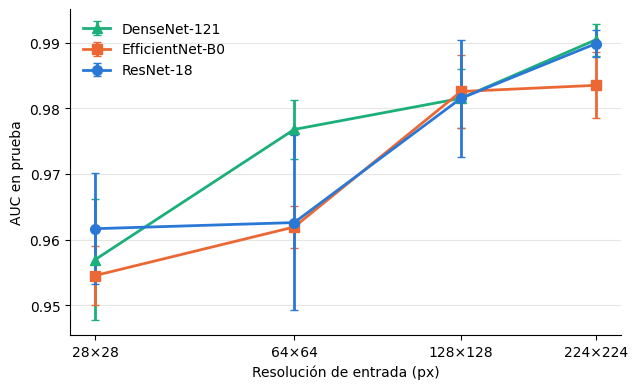

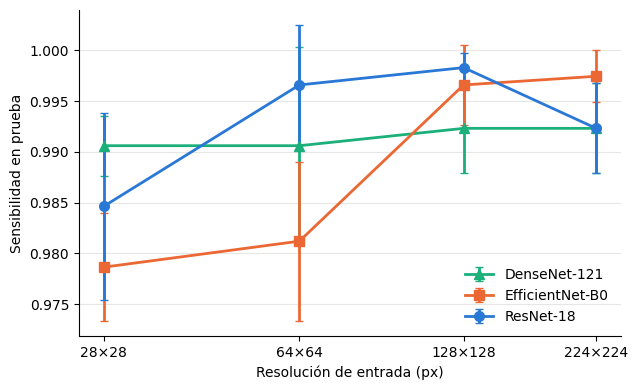

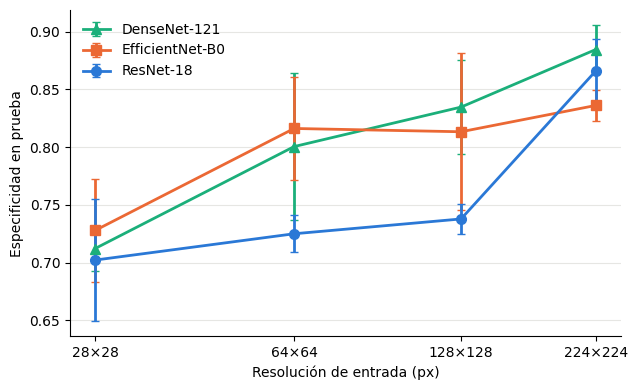

In [38]:
ev.plot_metric_vs_resolution(agregado, "auc", "AUC en prueba",
                             os.path.join(FIG_DIR, "fig4_auc_vs_resolucion.png"))
ev.plot_metric_vs_resolution(agregado, "sensibilidad", "Sensibilidad en prueba",
                             os.path.join(FIG_DIR, "fig5_sensibilidad_vs_resolucion.png"))
ev.plot_metric_vs_resolution(agregado, "especificidad", "Especificidad en prueba",
                             os.path.join(FIG_DIR, "fig6_especificidad_vs_resolucion.png"))



Figura: rendimiento frente a costo (para elegir el modelo de la app)

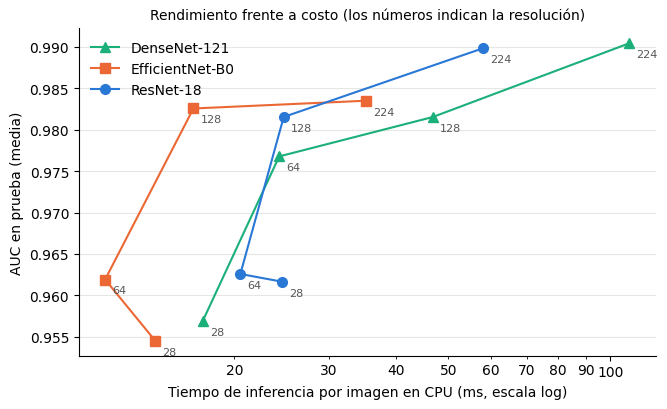

In [39]:
ev.plot_tradeoff(agregado, os.path.join(FIG_DIR, "fig7_auc_vs_latencia_cpu.png"))

Figuras: matrices de confusión y curvas ROC (semilla de referencia)

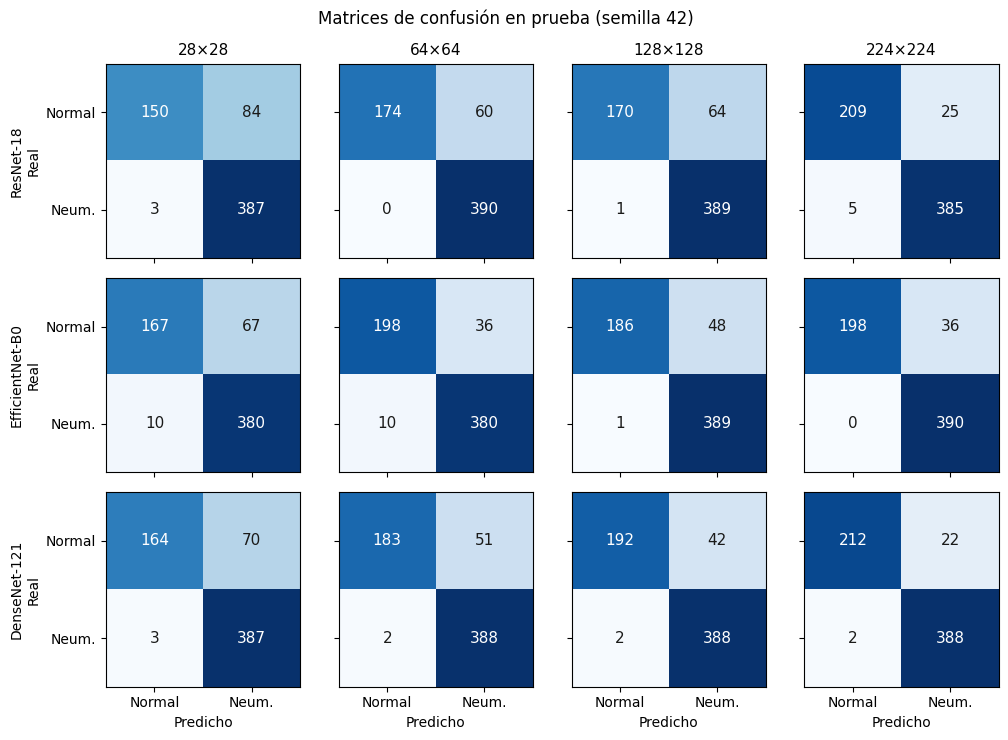

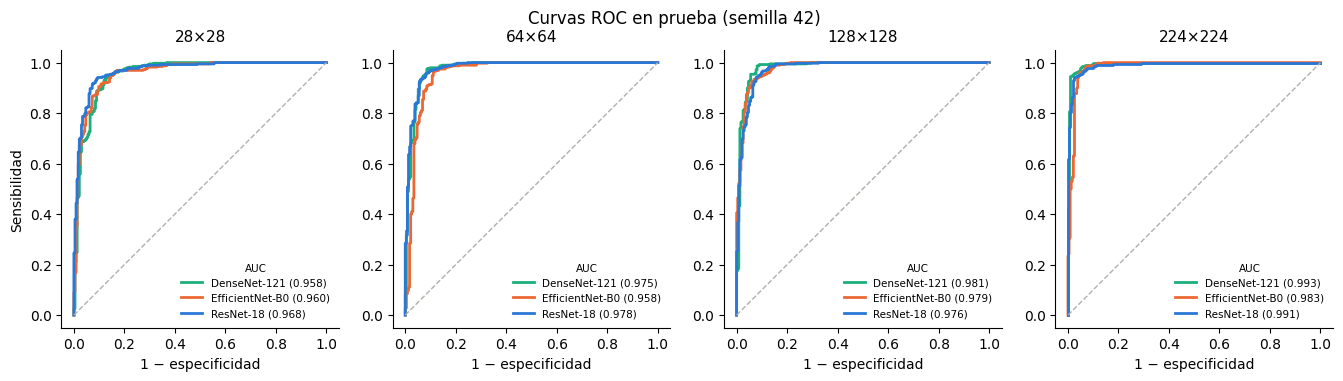

In [40]:
ev.plot_confusion_grid(por_corrida, SEED, os.path.join(FIG_DIR, "fig8_matrices_confusion.png"))
ev.plot_roc_by_resolution(por_corrida, RUNS_DIR, SEED, os.path.join(FIG_DIR, "fig9_curvas_roc.png"))


Candidatos para la app: configuraciones que cumplen ambos criterios, ordenadas por latencia en CPU (la más rápida primero)

In [41]:
best_auc = agregado.groupby("model")["auc_mean"].transform("max")
candidatos = agregado[(agregado["auc_mean"] >= best_auc - AUC_TOLERANCE)
                      & (agregado["sensibilidad_mean"] >= MIN_SENSITIVITY)]
cols = ["model", "size", "auc_mean", "sensibilidad_mean", "especificidad_mean",
        "tamano_MB", "latencia_cpu_ms"]
candidatos[cols].sort_values("latencia_cpu_ms").round(4)

,model,size,auc_mean,sensibilidad_mean,especificidad_mean,tamano_MB,latencia_cpu_ms
6,efficientnet_b0,128,0.9826,0.9966,0.8134,15.5812,16.7837
10,resnet18,128,0.9815,0.9983,0.7379,42.7141,24.7054
7,efficientnet_b0,224,0.9835,0.9974,0.8362,15.5812,35.1648
2,densenet121,128,0.9815,0.9923,0.8348,27.1092,46.7394
11,resnet18,224,0.9898,0.9923,0.8661,42.7141,58.0874
3,densenet121,224,0.9904,0.9923,0.8846,27.1092,108.5745


# Paso 4: explicabilidad con Grad-CAM.

Qué hace:
  - Grad-CAM sobre la clase "neumonía": muestra qué zonas de la radiografía
    empujan al modelo a decir neumonía.
  - Selecciona casos de prueba de los 4 tipos: verdaderos positivos (VP),
    verdaderos negativos (VN), falsos positivos (FP) y falsos negativos (FN).
  - Compara la misma radiografía en las 4 resoluciones.
  - Calcula una medida aproximada de "¿mira el centro del tórax o los bordes?".

**Limitación**:

Las tres redes reducen la imagen 32 veces en su última capa, así que el mapa de Grad-CAM mide 1×1 a 28 px, 2×2 a 64 px, 4×4 a 128 px y 7×7 a 224 px. A 28 px el mapa es uniforme y no explica nada. Con layer="intermedia" se usa una capa anterior (reducción 16×), que duplica el detalle: 2×2, 4×4, 8×8, 14×14.

In [42]:
%%writefile {PROJECT_DIR}/gradcam.py

import json
import os

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

import pneumonia_data as pdata
from evaluate import MODEL_STYLE, load_trained_model
from models import gradcam_target_layer
from train import get_device

GROUPS = {  # código -> (nombre para figuras, etiqueta real, predicción)
    "VP": ("Verdadero positivo", 1, 1),
    "VN": ("Verdadero negativo", 0, 0),
    "FP": ("Falso positivo", 0, 1),
    "FN": ("Falso negativo", 1, 0),
}


def target_layer(model, layer: str = "ultima"):
    """'ultima'     -> última capa convolucional (Grad-CAM estándar, reducción 32×).
    'intermedia' -> último bloque con reducción 16× (el doble de resolución espacial)."""
    if layer == "ultima":
        return gradcam_target_layer(model)
    if layer != "intermedia":
        raise ValueError("layer debe ser 'ultima' o 'intermedia'")
    net = model.net
    name = type(net).__name__
    if name == "ResNet":
        return net.layer3[-1]
    if name == "EfficientNet":
        return net.features[5]
    if name == "DenseNet":
        return net.features.denseblock3
    raise ValueError(f"Arquitectura no reconocida: {name}")


class GradCAM:
    """Grad-CAM (Selvaraju et al., 2017) sin dependencias externas.

    La capa objetivo devuelve una copia de su salida al resto de la red, para que
    operaciones in-place posteriores (p. ej. la ReLU final de DenseNet) no alteren
    las activaciones guardadas. Los gradientes se obtienen con torch.autograd.grad."""

    def __init__(self, model, layer_module, post_relu: bool = False):
        self.model = model.eval()
        self.post_relu = post_relu  # DenseNet aplica una ReLU funcional tras norm5
        self._acts = None
        self._handle = layer_module.register_forward_hook(self._hook)

    def _hook(self, module, inputs, output):
        if self.post_relu:
            output = F.relu(output)  # activaciones que realmente llegan al clasificador
        self._acts = output
        return output.clone()

    def remove(self):
        self._handle.remove()

    def __call__(self, x: torch.Tensor, class_idx: int = 1):
        """x: lote (B, 3, H, W) ya normalizado.
        Devuelve (cams, probs): cams (B, H, W) en [0, 1] y prob. de neumonía (B,)."""
        x = x.requires_grad_(False)
        with torch.enable_grad():
            logits = self.model(x)
            score = logits[:, class_idx].sum()  # las muestras son independientes (BN en eval)
            grads = torch.autograd.grad(score, self._acts)[0]
        weights = grads.mean(dim=(2, 3), keepdim=True)             # importancia de cada canal
        cam = F.relu((weights * self._acts).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
        flat = cam.flatten(1)
        lo, hi = flat.min(1)[0].view(-1, 1, 1), flat.max(1)[0].view(-1, 1, 1)
        cam = (cam - lo) / (hi - lo).clamp_min(1e-8)               # mapa uniforme -> ceros
        probs = torch.softmax(logits.detach().float(), dim=1)[:, 1]
        return cam.detach().cpu().numpy(), probs.cpu().numpy()


# ----------------------------------------------------------------------------
# Utilidades
# ----------------------------------------------------------------------------
def run_dir_of(runs_dir, model_name, size, seed):
    return os.path.join(runs_dir, f"{model_name}_{size}px_seed{seed}")


def load_predictions(run_dir: str):
    """Predicciones de prueba y umbral guardados en el paso 3."""
    pred = pd.read_csv(os.path.join(run_dir, "test_predictions.csv"))
    with open(os.path.join(run_dir, "test_metrics.json"), encoding="utf-8") as f:
        threshold = json.load(f)["umbral"]
    return pred, threshold


def select_cases(pred: pd.DataFrame, n_per_group: int = 3, mode: str = "confianza", seed: int = 42):
    """Elige n casos de prueba por grupo (VP, VN, FP, FN).
    mode='confianza': los casos en que el modelo estaba más seguro
                      (los errores más seguros son los más reveladores).
    mode='azar':      casos al azar, más representativos del comportamiento típico."""
    rng = np.random.default_rng(seed)
    cases = {}
    for code, (_, label, predicted) in GROUPS.items():
        d = pred[(pred["label"] == label) & (pred["pred"] == predicted)]
        if mode == "confianza":
            d = d.sort_values("prob_neumonia", ascending=(predicted == 0))
            chosen = d["index"].head(n_per_group).tolist()
        else:
            chosen = rng.choice(d["index"], size=min(n_per_group, len(d)), replace=False).tolist()
        cases[code] = [int(i) for i in chosen]
    return cases


def compute_cams(model, dataset, indices, layer: str = "ultima", batch_size: int = 16):
    """Grad-CAM para una lista de índices del conjunto de prueba."""
    device = next(model.parameters()).device
    post_relu = layer == "ultima" and type(model.net).__name__ == "DenseNet"
    cam_fn = GradCAM(model, target_layer(model, layer), post_relu=post_relu)
    cams, probs = [], []
    try:
        for start in range(0, len(indices), batch_size):
            idx = indices[start:start + batch_size]
            x = torch.stack([dataset[i][0] for i in idx]).to(device)
            c, p = cam_fn(x)
            cams.append(c)
            probs.append(p)
    finally:
        cam_fn.remove()
    return np.concatenate(cams), np.concatenate(probs)


def border_energy(cams: np.ndarray, margin: float = 0.15) -> np.ndarray:
    """Fracción de la 'atención' del Grad-CAM que cae en el borde exterior de la imagen
    (el `margin` de cada lado). En una radiografía de tórax centrada, el borde suele
    contener hombros, cuello, abdomen, letras o marcadores, no tejido pulmonar.
    Es una medida APROXIMADA: no reemplaza la revisión visual (sin máscaras de pulmón
    no se puede medir exactamente si el modelo mira los pulmones)."""
    h, w = cams.shape[-2:]
    mh, mw = int(round(h * margin)), int(round(w * margin))
    inner = np.zeros((h, w), dtype=bool)
    inner[mh:h - mh, mw:w - mw] = True
    total = cams.reshape(len(cams), -1).sum(1)
    outer = cams[:, ~inner].sum(1)
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(total > 0, outer / total, np.nan)


def border_area_fraction(margin: float = 0.15) -> float:
    """Fracción del área que ocupa el borde: es lo que daría un mapa uniforme."""
    return 1 - (1 - 2 * margin) ** 2


# ----------------------------------------------------------------------------
# Figuras
# ----------------------------------------------------------------------------
CMAP = "inferno"   # escala perceptualmente uniforme (más honesta que 'jet')


def _overlay(ax, img, cam, alpha=0.45):
    ax.imshow(img, cmap="gray", interpolation="bilinear")
    ax.imshow(cam, cmap=CMAP, alpha=alpha, vmin=0, vmax=1, interpolation="bilinear")
    ax.set_xticks([])
    ax.set_yticks([])


def plot_cases(model_name, size, seed, runs_dir, data_dir, path, n_per_group=3,
               mode="confianza", layer="ultima"):
    """Figura principal: filas = VP, VN, FP, FN; por cada caso, la radiografía original
    y su Grad-CAM. Devuelve una tabla con los casos mostrados."""
    import matplotlib.pyplot as plt
    device = get_device()
    rdir = run_dir_of(runs_dir, model_name, size, seed)
    pred, threshold = load_predictions(rdir)
    cases = select_cases(pred, n_per_group, mode, seed)
    model = load_trained_model(model_name, rdir, device)
    ds = pdata.load_split("test", size, data_dir, download=False, augment=False)

    flat = [(code, i) for code, idxs in cases.items() for i in idxs]
    cams, probs = compute_cams(model, ds, [i for _, i in flat], layer)

    fig, axes = plt.subplots(len(GROUPS), 2 * n_per_group,
                             figsize=(2.1 * 2 * n_per_group, 2.45 * len(GROUPS)), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    rows, k = [], 0
    for r, code in enumerate(GROUPS):
        for c, i in enumerate(cases[code]):
            img = ds.imgs[i]
            a0, a1 = axes[r, 2 * c], axes[r, 2 * c + 1]
            a0.axis("on"); a1.axis("on")
            a0.imshow(img, cmap="gray", interpolation="bilinear")
            a0.set_xticks([]); a0.set_yticks([])
            _overlay(a1, img, cams[k])
            a0.set_title(f"#{i}", fontsize=8, color="#555")
            a1.set_title(f"P(neum.) = {probs[k]:.2f}", fontsize=8)
            rows.append({"grupo": code, "indice_test": i, "prob_neumonia": float(probs[k]),
                         "energia_borde": float(border_energy(cams[k:k + 1])[0])})
            k += 1
        axes[r, 0].axis("on")
        axes[r, 0].set_ylabel(f"{GROUPS[code][0]}\n({code})", fontsize=9)
        if not cases[code]:
            axes[r, 0].text(0.5, 0.5, "sin casos", ha="center", va="center", fontsize=9)
            axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([])
            for s in axes[r, 0].spines.values():
                s.set_visible(False)
    st = MODEL_STYLE[model_name]["label"]
    fig.suptitle(f"Grad-CAM · {st} · {size}×{size} px · semilla {seed} · umbral {threshold:.2f}"
                 f"\n(pares: original | Grad-CAM de la clase neumonía)", fontsize=11)
    _add_colorbar(fig, axes)
    plt.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()
    del model
    return pd.DataFrame(rows)


def plot_resolution_comparison(model_name, seed, sizes, indices, runs_dir, data_dir, path,
                               layer="ultima"):
    """La misma radiografía en cada resolución, cada una con el Grad-CAM de su
    propio modelo entrenado. Muestra cómo cambia la explicación con la resolución."""
    import matplotlib.pyplot as plt
    device = get_device()
    fig, axes = plt.subplots(len(indices), len(sizes), figsize=(2.4 * len(sizes), 2.5 * len(indices)),
                             squeeze=False)
    labels = None
    for c, size in enumerate(sizes):
        rdir = run_dir_of(runs_dir, model_name, size, seed)
        model = load_trained_model(model_name, rdir, device)
        ds = pdata.load_split("test", size, data_dir, download=False, augment=False)
        labels = ds.labels.ravel()
        cams, probs = compute_cams(model, ds, list(indices), layer)
        for r, i in enumerate(indices):
            ax = axes[r, c]
            _overlay(ax, ds.imgs[i], cams[r])
            ax.set_title(f"{size}×{size} · P={probs[r]:.2f}", fontsize=9)
            if cams[r].max() == 0:  # mapa 1×1 (o sin activación): no hay explicación espacial
                ax.text(0.5, 0.5, "mapa uniforme\n(sin información\nespacial)", transform=ax.transAxes,
                        ha="center", va="center", fontsize=8, color="white",
                        bbox=dict(facecolor="black", alpha=0.6, edgecolor="none"))
        del model
    for r, i in enumerate(indices):
        axes[r, 0].set_ylabel(f"#{i}\n{pdata.CLASS_NAMES[labels[i]]}", fontsize=9)
    st = MODEL_STYLE[model_name]["label"]
    capa = "última capa" if layer == "ultima" else "capa intermedia"
    fig.suptitle(f"Grad-CAM según la resolución · {st} · {capa} · semilla {seed}", fontsize=11)
    _add_colorbar(fig, axes)
    plt.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()


def border_energy_table(model_names, sizes, seed, runs_dir, data_dir, layer="ultima",
                        margin=0.15) -> pd.DataFrame:
    """Energía en el borde sobre TODO el conjunto de prueba, por modelo, resolución y grupo.
    Referencia: un mapa uniforme tendría border_area_fraction(margin) (≈0.51 con 0.15).
    Valores claramente menores indican que el modelo se concentra en el centro del tórax."""
    device = get_device()
    rows = []
    for name in model_names:
        for size in sizes:
            rdir = run_dir_of(runs_dir, name, size, seed)
            if not os.path.exists(os.path.join(rdir, "test_predictions.csv")):
                continue
            pred, _ = load_predictions(rdir)
            model = load_trained_model(name, rdir, device)
            ds = pdata.load_split("test", size, data_dir, download=False, augment=False)
            cams, _ = compute_cams(model, ds, pred["index"].tolist(), layer)
            energy = border_energy(cams, margin)
            pred = pred.assign(energia_borde=energy)
            for code, (_, label, predicted) in GROUPS.items():
                d = pred[(pred["label"] == label) & (pred["pred"] == predicted)]
                rows.append({"model": name, "size": size, "grupo": code, "n": len(d),
                             "energia_borde_media": d["energia_borde"].mean()})
            rows.append({"model": name, "size": size, "grupo": "todos", "n": len(pred),
                         "energia_borde_media": pred["energia_borde"].mean()})
            print(f"{name:<16} {size:>3}px | energía en el borde (media) "
                  f"{pred['energia_borde'].mean():.3f}")
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    return pd.DataFrame(rows)


def _add_colorbar(fig, axes):
    import matplotlib.pyplot as plt
    from matplotlib.cm import ScalarMappable
    from matplotlib.colors import Normalize
    plt.tight_layout(rect=(0, 0, 0.93, 1))
    cax = fig.add_axes([0.945, 0.25, 0.012, 0.5])
    cb = fig.colorbar(ScalarMappable(Normalize(0, 1), CMAP), cax=cax)
    cb.set_label("Importancia para «neumonía»", fontsize=9)
    cb.ax.tick_params(labelsize=8)


Writing /content/drive/MyDrive/neumonia_resolucion/gradcam.py


In [43]:
import os, sys
import pandas as pd

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)
for name in ("pneumonia_data", "models", "train", "evaluate", "gradcam"):
    sys.modules.pop(name, None)
import pneumonia_data as pdata, models, train, evaluate as ev, gradcam as gc

RUNS_DIR = os.path.join(PROJECT_DIR, "outputs", "runs")
EVAL_DIR = os.path.join(PROJECT_DIR, "outputs", "evaluacion")
FIG_DIR = os.path.join(PROJECT_DIR, "outputs", "figuras")
print("Dispositivo:", train.get_device())


Dispositivo: cuda


Configuración

In [44]:
MODELO = "efficientnet_b0"    # "resnet18", "efficientnet_b0" o "densenet121"
RESOLUCION = 224              # a 28 px el Grad-CAM de la última capa es uniforme (mapa 1×1)
CAPA = "ultima"               # "ultima" (estándar) o "intermedia" (doble de detalle espacial)
N_POR_GRUPO = 3               # casos por grupo: VP, VN, FP, FN

pred, umbral = gc.load_predictions(gc.run_dir_of(RUNS_DIR, MODELO, RESOLUCION, SEED))
print(f"Umbral de decisión (elegido en validación): {umbral:.3f}")
print(pred.assign(grupo=pred["label"].astype(str) + "->" + pred["pred"].astype(str))
          ["grupo"].value_counts().rename({"1->1": "VP", "0->0": "VN", "0->1": "FP", "1->0": "FN"}))

Umbral de decisión (elegido en validación): 0.890
grupo
VP    390
VN    198
FP     36
Name: count, dtype: int64


Figura principal: aciertos y errores más seguros del modelo

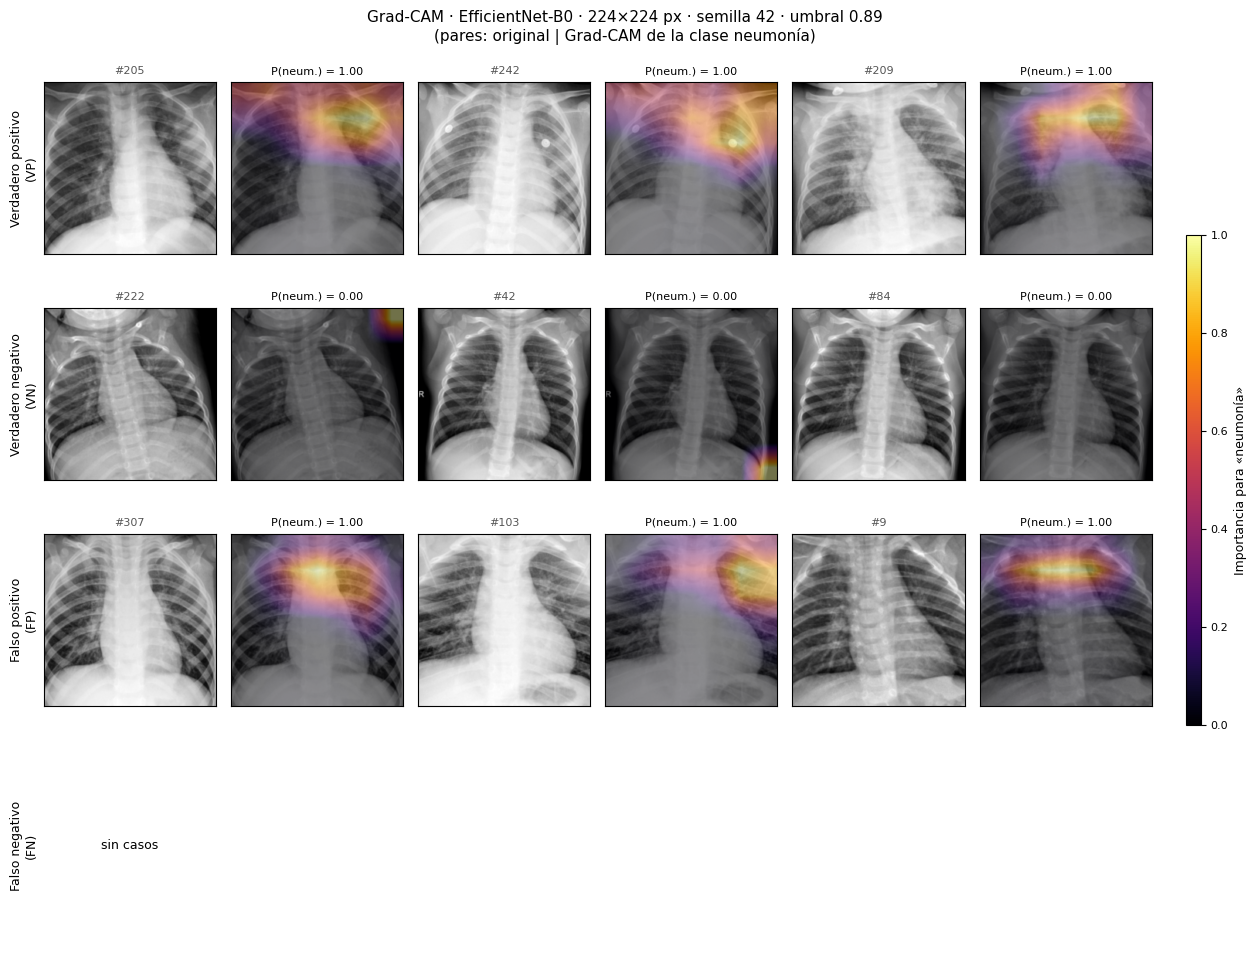

,grupo,indice_test,prob_neumonia,energia_borde
0,VP,205,9.999998e-01,0.523409
1,VP,242,9.999998e-01,0.513111
2,VP,209,9.999998e-01,0.380171
3,VN,222,7.350458e-11,0.990841
4,VN,42,8.101172e-11,0.990841
5,VN,84,1.522874e-10,NaN
6,FP,307,9.999952e-01,0.277943
7,FP,103,9.999921e-01,0.532889
8,FP,9,9.999847e-01,0.338394


In [45]:
casos = gc.plot_cases(MODELO, RESOLUCION, SEED, RUNS_DIR, DATA_DIR,
                      os.path.join(FIG_DIR, f"fig10_gradcam_casos_{MODELO}_{RESOLUCION}.png"),
                      n_per_group=N_POR_GRUPO, mode="confianza", layer=CAPA)
casos

Los mismos grupos con casos al azar (más representativos que los extremos)

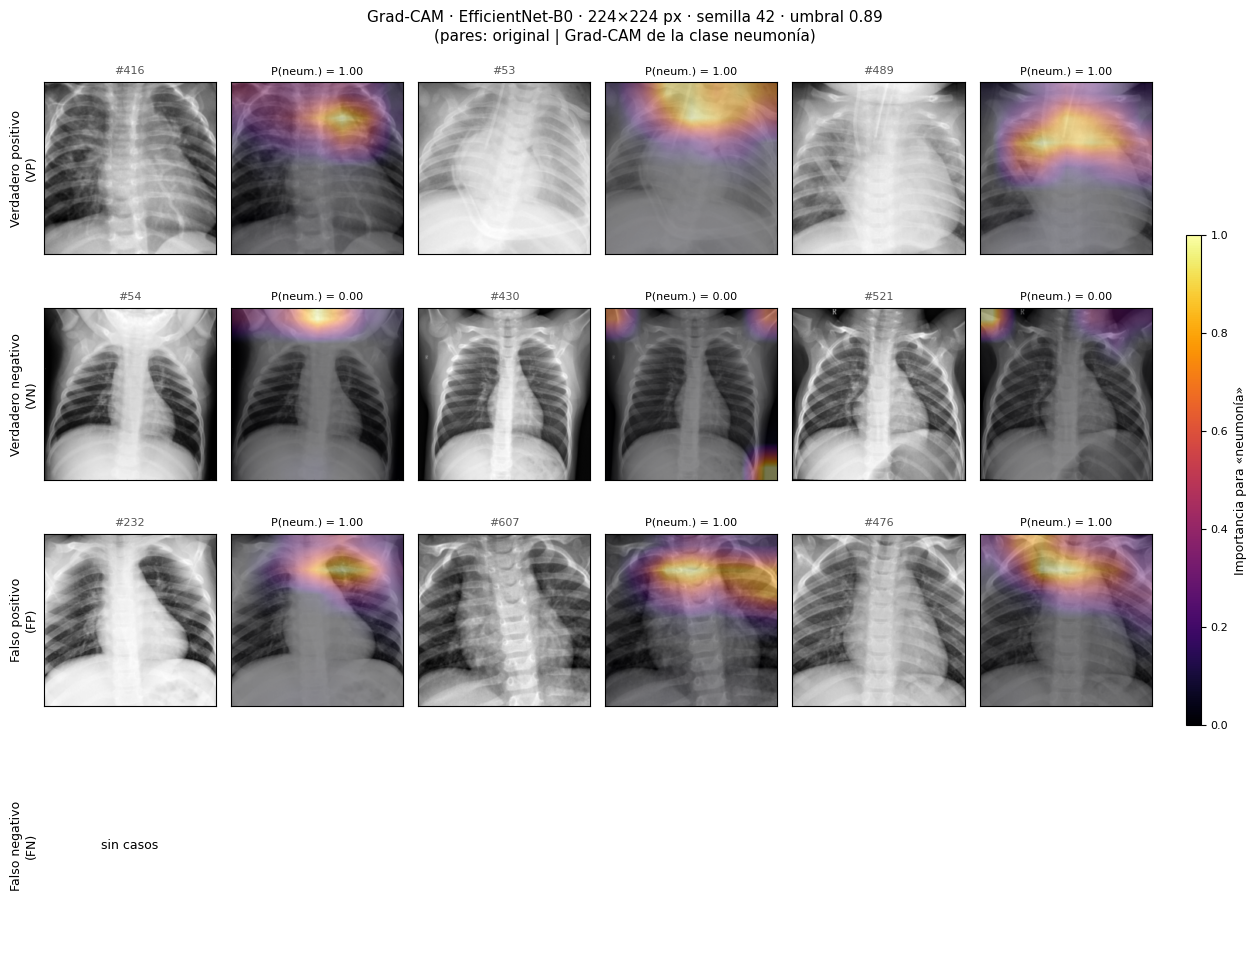

,grupo,indice_test,prob_neumonia,energia_borde
0,VP,416,9.999883e-01,0.431595
1,VP,53,9.999992e-01,0.566750
2,VP,489,9.999551e-01,0.278441
3,VN,54,8.218039e-04,0.919126
4,VN,430,8.826713e-10,0.989403
5,VN,521,1.794192e-06,0.900007
6,FP,232,9.965083e-01,0.434435
7,FP,607,9.998901e-01,0.394755
8,FP,476,9.991440e-01,0.491954


In [46]:
gc.plot_cases(MODELO, RESOLUCION, SEED, RUNS_DIR, DATA_DIR,
              os.path.join(FIG_DIR, f"fig11_gradcam_azar_{MODELO}_{RESOLUCION}.png"),
              n_per_group=N_POR_GRUPO, mode="azar", layer=CAPA)

Misma radiografía en las 4 resoluciones (relaciona explicabilidad y resolución)

Usa dos aciertos de neumonía de la figura principal y un verdadero negativo.

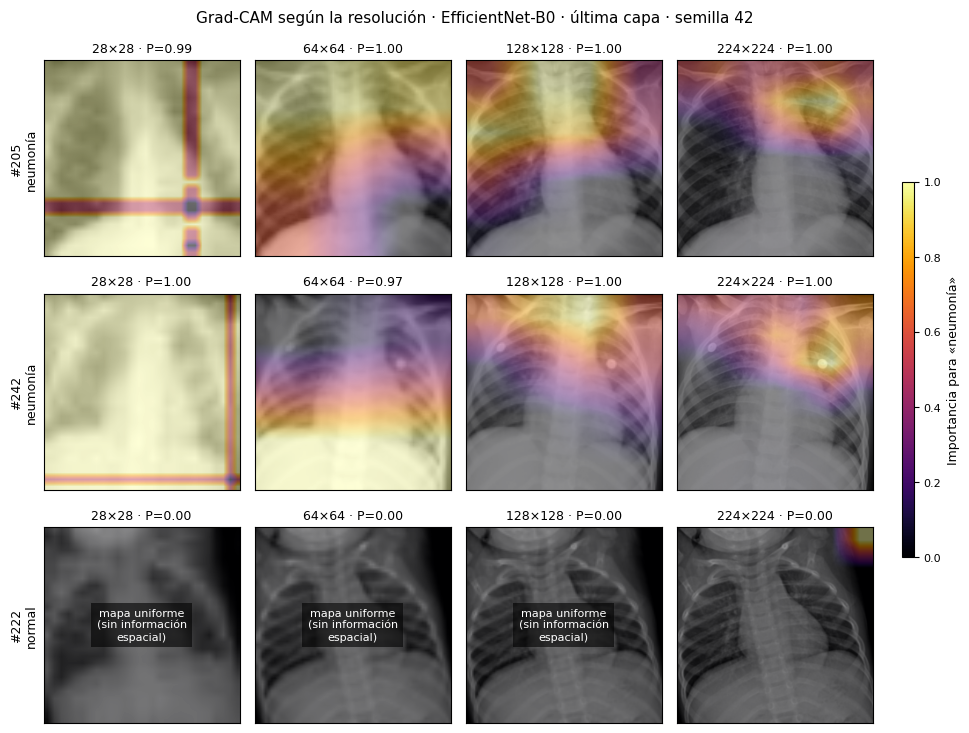

In [47]:
indices = casos.query("grupo == 'VP'")["indice_test"].head(2).tolist() \
        + casos.query("grupo == 'VN'")["indice_test"].head(1).tolist()
gc.plot_resolution_comparison(MODELO, SEED, SIZES, indices, RUNS_DIR, DATA_DIR,
                              os.path.join(FIG_DIR, f"fig12_gradcam_resoluciones_{MODELO}.png"),
                              layer=CAPA)

Medida aproximada sobre TODO el conjunto de prueba: ¿cuánta atención cae en los bordes?

In [48]:
# Un mapa uniforme daría ~0.51 (el borde del 15% ocupa el 51% del área).
# Valores claramente menores = el modelo se concentra en el centro del tórax.
# A 28 px el mapa es uniforme y no se puede interpretar: por eso se excluye.
energia = gc.border_energy_table(models.MODEL_NAMES, [s for s in SIZES if s > 28], SEED,
                                 RUNS_DIR, DATA_DIR, layer=CAPA)
energia.to_csv(os.path.join(EVAL_DIR, "gradcam_energia_borde.csv"), index=False)
print(f"Referencia (mapa uniforme): {gc.border_area_fraction():.2f}")
energia.pivot_table(index=["model", "size"], columns="grupo",
                    values="energia_borde_media").round(3)[["VP", "VN", "FP", "FN", "todos"]]

resnet18          64px | energía en el borde (media) 0.527
resnet18         128px | energía en el borde (media) 0.411
resnet18         224px | energía en el borde (media) 0.558
efficientnet_b0   64px | energía en el borde (media) 0.527
efficientnet_b0  128px | energía en el borde (media) 0.566
efficientnet_b0  224px | energía en el borde (media) 0.464
densenet121       64px | energía en el borde (media) 0.527
densenet121      128px | energía en el borde (media) 0.412
densenet121      224px | energía en el borde (media) 0.475
Referencia (mapa uniforme): 0.51


grupo                    VP     VN     FP     FN  todos
model           size                                   
densenet121     64    0.527  0.527  0.527  0.527  0.527
                128   0.356  0.744  0.421  0.723  0.412
                224   0.396  0.824  0.417  0.065  0.475
efficientnet_b0 64    0.527  0.527  0.527  0.527  0.527
                128   0.521  0.738  0.545  0.522  0.566
                224   0.426  0.571  0.342    NaN  0.464
resnet18        64    0.527  0.527  0.527    NaN  0.527
                128   0.351  0.765  0.444  0.700  0.411
                224   0.442  0.790  0.431  0.573  0.558